In [45]:
## UAS-guided Airborne MSI for LAI modeling in low-stature shrubland vegetation.
## Author: Ramesh Bhatta, RIT
## Contact: rb1005@rit.edu

"""
C. AVIRIS-NG Simulated MSI data for LAI modeling. Here we will utilize the UAS-MSI data to harmonize airborne MSI data,
extracted from the AVIRIS-NG bands to analyze and model LAI in the Fynbos vegetation.
"""

## Importing libraries
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as mcolors
import seaborn as sns
import pandas as pd
import folium
import os
import rasterio
from rasterio.mask import mask
import geopandas as gpd
import itertools
from netCDF4 import Dataset
from shapely.ops import transform
from sklearn.model_selection import LeaveOneOut
from shapely.geometry import Point, box, Polygon
from scipy.stats import linregress, pearsonr, skew
from scipy.optimize import curve_fit
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.linear_model import RANSACRegressor, LinearRegression

In [46]:
## C1. Extract spectra corresponding to the field LAI measurement locations

LAI_measurement_shapefile = './ground_LAI_data_processed/5mx5m_LAI_plots.shp'
lai_gdf = gpd.read_file(LAI_measurement_shapefile)
print(lai_gdf.head())

   plot_id  LAI_mean    LAI_sd  n_reps   lon_mean   lat_mean  \
0  GBS0619  2.112576  0.371472       3  19.417133 -34.531937   
1  GBS0622  2.348314  0.658946       3  19.416763 -34.532163   
2  GBS0625  1.575255  0.150760       3  19.416767 -34.531720   
3  GBS0626  1.790895  0.190132       3  19.417487 -34.532730   
4  GBS0627  1.413221  0.461606       3  19.416707 -34.532463   

                                            geometry  
0  POLYGON ((354738.981 6177726.267, 354738.981 6...  
1  POLYGON ((354705.416 6177700.597, 354705.416 6...  
2  POLYGON ((354704.952 6177749.769, 354704.952 6...  
3  POLYGON ((354772.788 6177638.792, 354772.788 6...  
4  POLYGON ((354700.736 6177667.245, 354700.736 6...  


In [47]:
## AVIRIS-NG sampled MSI bands for LAI modeling

## C2. Load the AVIRIS-NG rasters

raster_files = [
    "./AVIRIS_NG_data/ang20231031t092656_002_L2B_OE_0b4f48b4_RFL_ORT_tbg_v1.nc",
    "./AVIRIS_NG_data/ang20231109t062226_001_L2B_OE_0b4f48b4_RFL_ORT_tbg_v1.nc",
    "./AVIRIS_NG_data/ang20231109t062226_002_L2B_OE_0b4f48b4_RFL_ORT_tbg_v1.nc",
    "./AVIRIS_NG_data/ang20231117t123306_001_L2B_OE_0b4f48b4_RFL_ORT_tbg_v1.nc"
]


## Load LAI ground measurements shapefile
gdf = gpd.read_file(LAI_measurement_shapefile)

In [48]:
## C3. Extract AVIRIS-NG spectra at the LAI plot locations

# Create a dictionary to hold candidate spectra for each plot
candidates = {pid: [] for pid in gdf['plot_id'].unique()}
wavelengths = None

print(f"Starting Extraction for {len(gdf)} plots...")

# Main loop through raster files
for nc_file in raster_files:
    if os.path.exists(nc_file):
        actual_path = nc_file
    elif os.path.exists(os.path.basename(nc_file)):
        actual_path = os.path.basename(nc_file)
    else: continue

    netcdf_path = f"NETCDF:{actual_path}:/reflectance/reflectance"

    try:
        with rasterio.open(netcdf_path) as src:
            # 1. Capture wavelengths
            if wavelengths is None:
                with Dataset(actual_path, mode="r") as ds:
                    wavelengths = ds.groups["reflectance"].variables["wavelength"][:]

            # 2. Project plots to match raster CRS
            gdf_local = gdf.to_crs(src.crs)

            # 3. Iterate plots
            for idx, row in gdf_local.iterrows():
                geom = row.geometry
                bounds = src.bounds
                
                # Check if plot is within image extents
                if not box(bounds.left, bounds.bottom, bounds.right, bounds.top).intersects(geom):
                    continue

                try:
                    # ATTEMPT 1: Exact polygon mask
                    # all_touched=True ensures we grab pixels on the edges
                    out_image, _ = mask(src, [geom], crop=True, all_touched=True, nodata=-9999)
                    data = out_image.reshape(out_image.shape[0], -1)
                    
                    # Filter valid pixels (using band 100 as a check)
                    valid_mask = (data[100, :] > -50) 
                    valid_pixels = data[:, valid_mask]
                    
                    # ATTEMPT 2: Centroid fallback if no valid pixels from polygon
                    # If the polygon mask failed (0 pixels), grab the center pixel ONLY
                    if valid_pixels.shape[1] == 0:
                        cx, cy = geom.centroid.x, geom.centroid.y
                        r, c = src.index(cx, cy)
                        # Ensure centroid is inside the image grid
                        if 0 <= r < src.height and 0 <= c < src.width:
                            window = rasterio.windows.Window(c, r, 1, 1)
                            centroid_data = src.read(window=window).reshape(src.count, -1)
                            if np.all(centroid_data[100, :] > -50):
                                valid_pixels = centroid_data

                    # Save valid spectra if we have any
                    if valid_pixels.shape[1] > 0:
                        mean_spectrum = np.mean(valid_pixels, axis=1)
                        img_cx, img_cy = (bounds.left + bounds.right)/2, (bounds.top + bounds.bottom)/2
                        dist = np.sqrt((geom.centroid.x - img_cx)**2 + (geom.centroid.y - img_cy)**2)
                        
                        candidates[row['plot_id']].append({
                            'spectrum': mean_spectrum,
                            'dist': dist,
                            'file': os.path.basename(actual_path),
                            'pixels': valid_pixels.shape[1]
                        })
                        
                except Exception:
                    continue

    except Exception as e:
        print(f"  [ERROR] {os.path.basename(actual_path)}: {e}")

# Finalize records by picking the best spectrum for each plot
final_records = []
for pid, data_list in candidates.items():
    if not data_list:
        print(f"  [FAILED] Plot {pid}: No data found.")
        continue
    
    data_list.sort(key=lambda x: x['dist']) # Pick the nadir-most flightline
    best = data_list[0]
    
    rec = {
        'plot_id': pid, 'source_file': best['file'], 
        'dist_to_center': round(best['dist'], 1), 'pixels_used': best['pixels']
    }
    for i, val in enumerate(best['spectrum']):
        rec[f'band_{i}'] = val
    final_records.append(rec)

df_spectra = pd.DataFrame(final_records)
print(f"Extraction Complete: {len(df_spectra)} / {len(gdf)} plots.")

Starting Extraction for 20 plots...
Extraction Complete: 20 / 20 plots.


Plotting all spectral signatures...


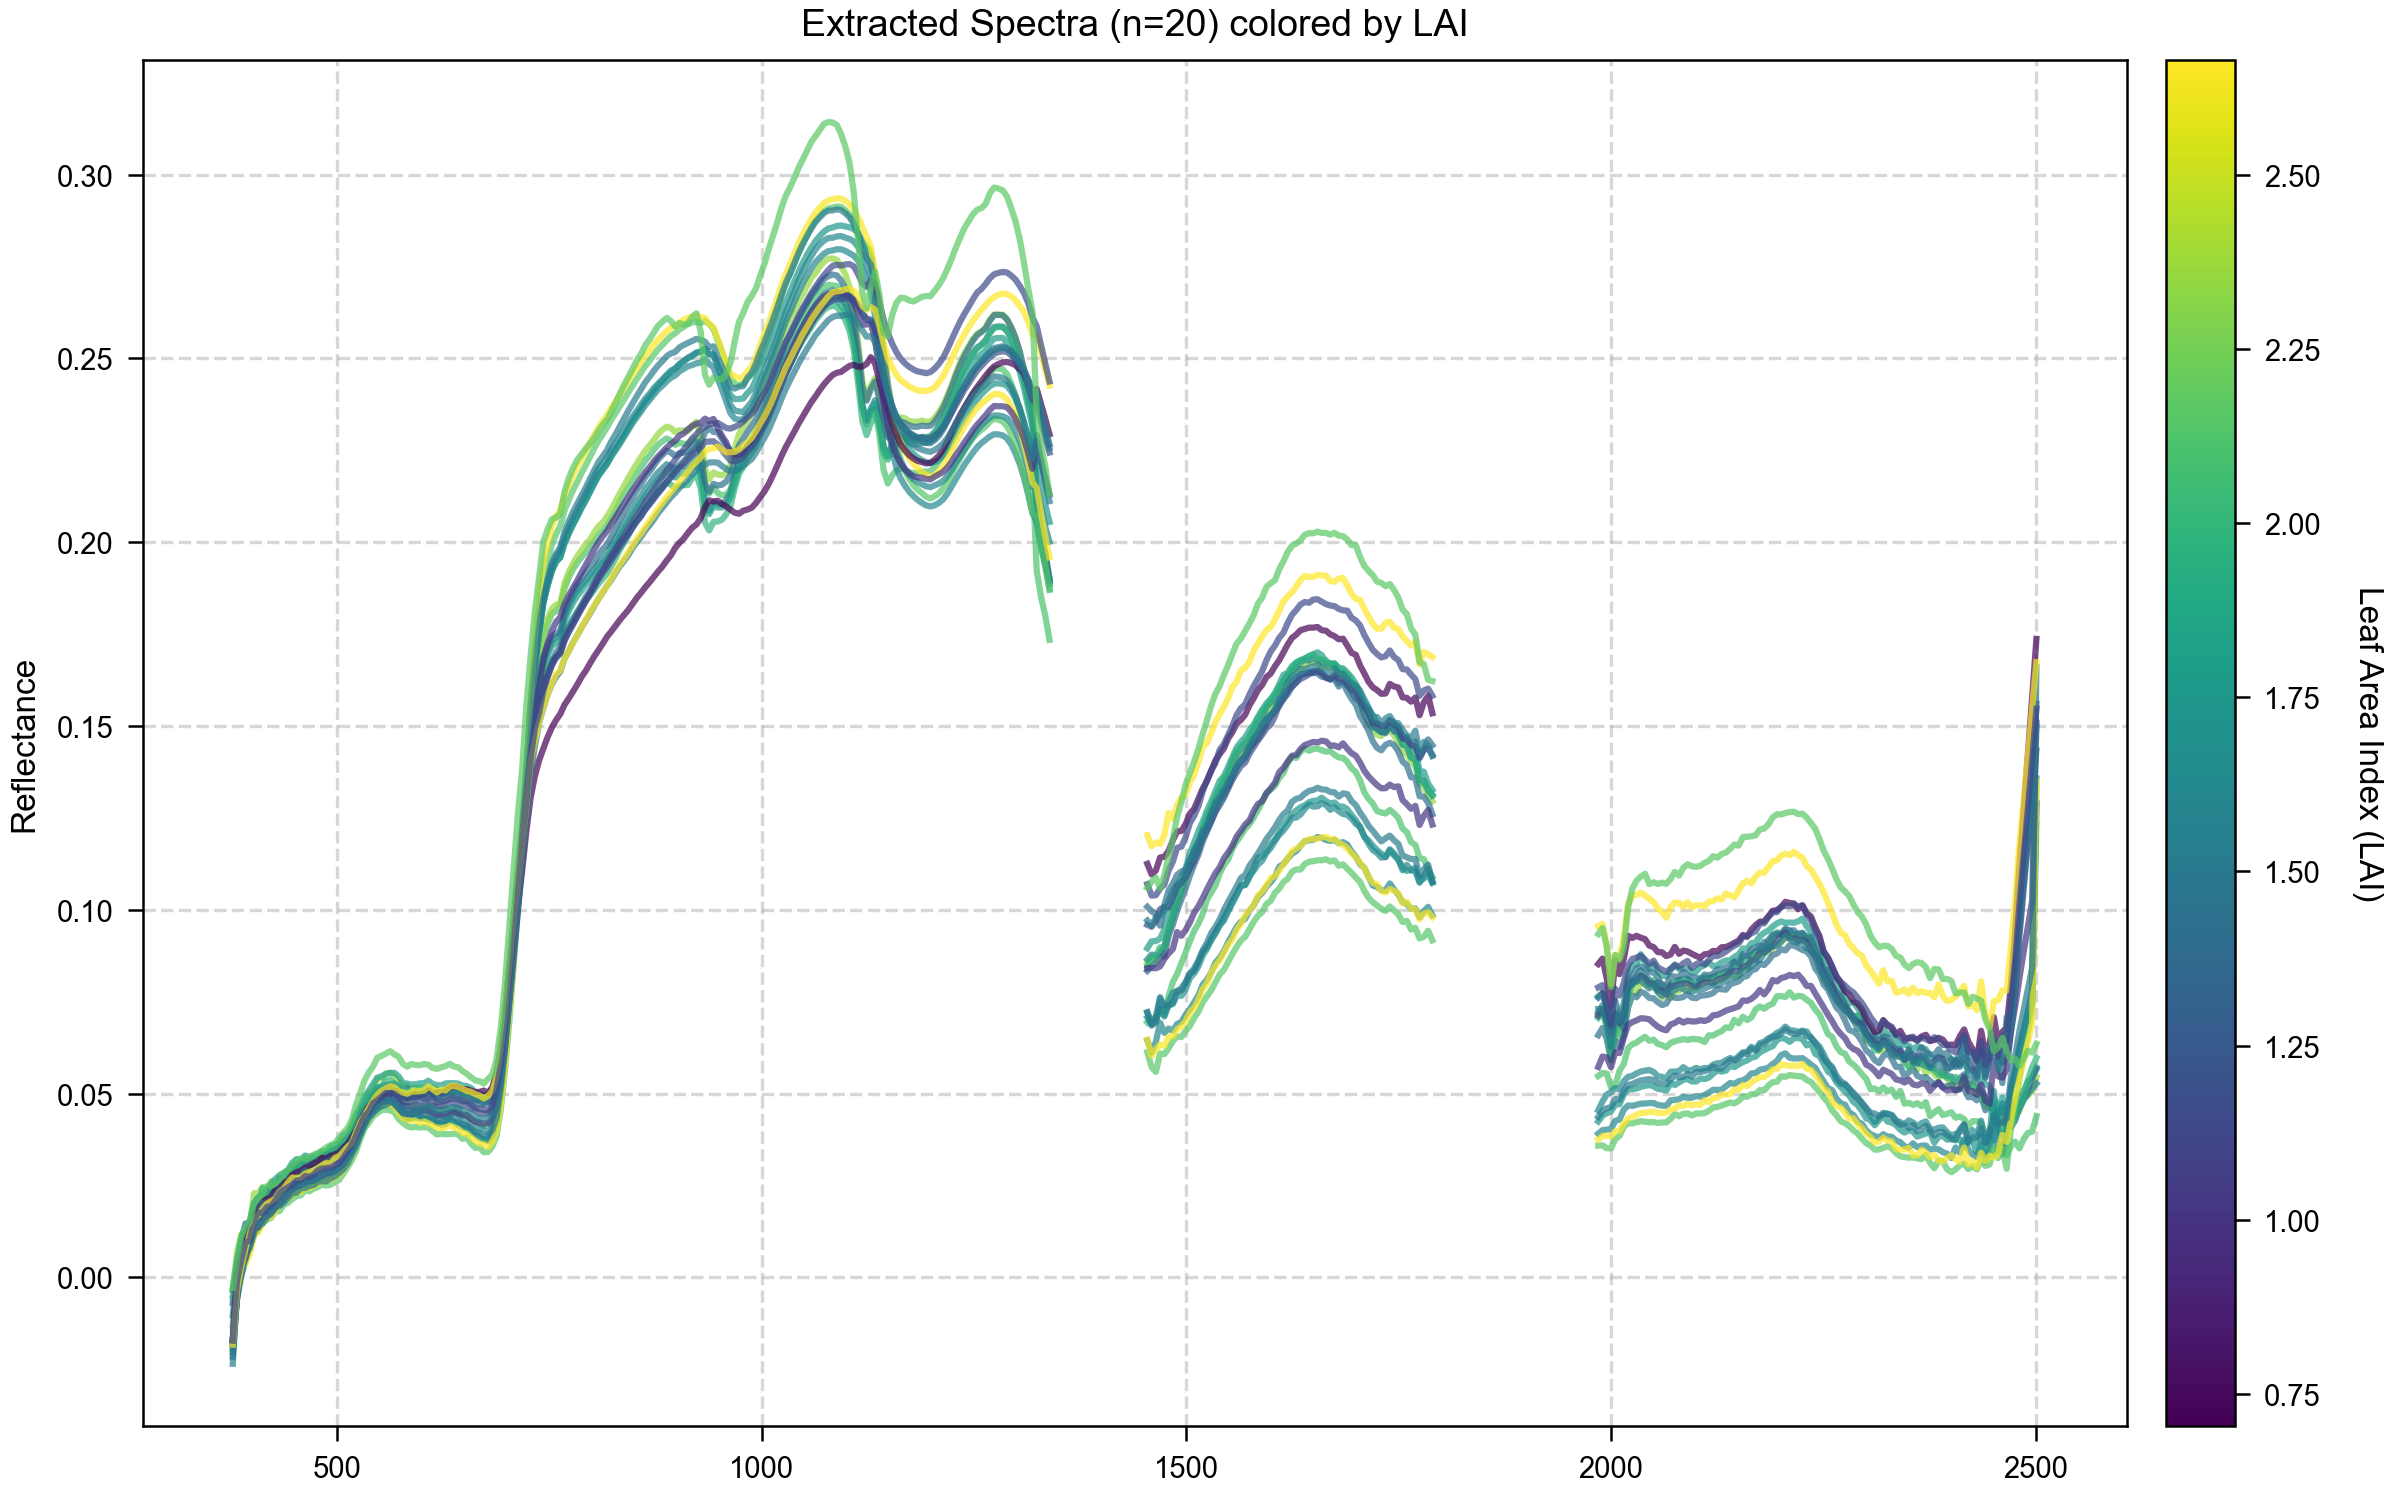

In [49]:
## C4. Visualize the extracted spectra at the ground plot locations.

# Ensure we have the LAI values attached to the spectra
plot_data = df_spectra.merge(gdf[['plot_id', 'LAI_mean']], on='plot_id', how='left')
band_cols = sorted([c for c in plot_data.columns if c.startswith('band_')], 
                   key=lambda x: int(x.split('_')[1]))

X_plot = plot_data[band_cols].values
lai_values = plot_data['LAI_mean'].values

# Plotting setup
fig, ax = plt.subplots(figsize=(8, 5), constrained_layout=True)
norm = mcolors.Normalize(vmin=np.nanmin(lai_values), vmax=np.nanmax(lai_values)) # Color map based on LAI values
cmap = cm.viridis
print(f"Plotting all spectral signatures...")

for i in range(len(X_plot)):
    # Get spectrum and LAI
    spectrum = X_plot[i]
    lai = lai_values[i]
    
    # Mask out "bad" water absorption bands for cleaner plotting
    # Common AVIRIS-NG bad bands: ~1350-1420nm and ~1800-1950nm
    spectrum_masked = spectrum.copy()
    
    # Identify indices of water bands (approximate)
    bad_indices = np.where(
        ((wavelengths > 1340) & (wavelengths < 1450)) | 
        ((wavelengths > 1790) & (wavelengths < 1980))
    )[0]
    spectrum_masked[bad_indices] = np.nan
    
    # Plot line
    color = cmap(norm(lai))
    ax.plot(wavelengths, spectrum_masked, color=color, alpha=0.7, linewidth=1.5)


# Add colorbar for LAI
sm = cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = fig.colorbar(sm, ax=ax, orientation='vertical', pad=0.02)
cbar.set_label('Leaf Area Index (LAI)', rotation=270, labelpad=15)
ax.set_title(f"Extracted Spectra (n={len(X_plot)}) colored by LAI")
ax.set_ylabel("Reflectance")
ax.set_label("Wavelength (nm)")
ax.grid(which = 'both', linestyle='--', alpha=0.5)
plt.show()

In [50]:
## Print the dataframe with 20 ground plots.

plot_data

,plot_id,source_file,dist_to_center,pixels_used,band_0,band_1,band_2,band_3,band_4,band_5,...,band_416,band_417,band_418,band_419,band_420,band_421,band_422,band_423,band_424,LAI_mean
0,GBS0619,ang20231031t092656_002_L2B_OE_0b4f48b4_RFL_ORT...,2069.8,2,-0.012839,-0.000597,0.005537,0.009045,0.011444,0.016510,...,0.035863,0.033181,0.035569,0.036930,0.035091,0.037592,0.039288,0.039655,0.043875,2.112576
1,GBS0622,ang20231031t092656_002_L2B_OE_0b4f48b4_RFL_ORT...,2033.0,1,-0.003114,0.006765,0.011716,0.010504,0.014015,0.022895,...,0.046204,0.038042,0.046299,0.044567,0.045119,0.048770,0.049470,0.050644,0.054497,2.348314
2,GBS0625,ang20231031t092656_002_L2B_OE_0b4f48b4_RFL_ORT...,2078.1,2,-0.010381,-0.000451,0.009333,0.011443,0.013812,0.019793,...,0.046227,0.043486,0.043235,0.043492,0.046015,0.048172,0.049881,0.051346,0.052706,1.575255
3,GBS0626,ang20231031t092656_002_L2B_OE_0b4f48b4_RFL_ORT...,2004.2,4,-0.003502,0.003047,0.009716,0.012301,0.015389,0.020258,...,0.048921,0.044205,0.044812,0.047745,0.049028,0.050746,0.053250,0.054480,0.056589,1.790895
4,GBS0627,ang20231031t092656_002_L2B_OE_0b4f48b4_RFL_ORT...,2000.4,4,-0.006965,0.004148,0.010290,0.014685,0.014490,0.018344,...,0.042140,0.041345,0.040841,0.042606,0.046406,0.048729,0.050940,0.054166,0.057023,1.413221
5,GBS06P,ang20231031t092656_002_L2B_OE_0b4f48b4_RFL_ORT...,2099.4,2,-0.005079,-0.000273,0.010613,0.010944,0.014199,0.019529,...,0.038917,0.041805,0.041572,0.043249,0.046657,0.048604,0.053699,0.057122,0.059680,1.977499
6,GBS161,ang20231117t123306_001_L2B_OE_0b4f48b4_RFL_ORT...,956.4,4,-0.019429,-0.003855,0.000484,0.004669,0.008724,0.011589,...,0.033406,0.037939,0.050893,0.055695,0.061688,0.066478,0.071469,0.076401,0.128763,1.603689
7,GBS162,ang20231117t123306_001_L2B_OE_0b4f48b4_RFL_ORT...,1105.2,2,-0.017971,-0.004858,0.002037,0.005088,0.007893,0.011398,...,0.035306,0.029535,0.040353,0.046807,0.053974,0.060246,0.066512,0.072966,0.123309,2.146058
8,GBS164,ang20231117t123306_001_L2B_OE_0b4f48b4_RFL_ORT...,955.4,4,-0.016836,-0.006069,0.003055,0.005517,0.008959,0.012046,...,0.036427,0.040728,0.051072,0.054738,0.061019,0.065443,0.069919,0.074534,0.135696,1.737210
9,GBS168,ang20231117t123306_001_L2B_OE_0b4f48b4_RFL_ORT...,1072.7,2,-0.018575,-0.005444,0.001595,0.004601,0.009180,0.011785,...,0.047335,0.041761,0.051851,0.056210,0.062712,0.067510,0.072588,0.077806,0.129008,1.622965


In [51]:
# C5. Simulate DJI Mavic 3M MSI bands from AVIRIS-NG using nominal rectangular bandpass averaging

# DJI Mavic 3M nominal band centers and bandwidths
drone_bands = {
    "Green":   {"center": 560, "tolerance": 16},  # 544–576 nm
    "Red":     {"center": 650, "tolerance": 16},  # 634–666 nm
    "RedEdge": {"center": 730, "tolerance": 16},  # 714–746 nm
    "NIR":     {"center": 860, "tolerance": 26}   # 834–886 nm
}

# Make sure wavelengths is a 1D numpy array in nm
wavelengths = np.asarray(wavelengths, dtype=float)

# Identify AVIRIS-NG bands falling within each UAS nominal band window
aviris_band_indices = {}

print("--- Simulating DJI Mavic 3M bands using nominal rectangular bandpass averaging ---")

for band_name, specs in drone_bands.items():
    min_wl = specs["center"] - specs["tolerance"]
    max_wl = specs["center"] + specs["tolerance"]

    indices = np.where((wavelengths >= min_wl) & (wavelengths <= max_wl))[0]

    if len(indices) == 0:
        raise ValueError(f"No AVIRIS-NG bands found for {band_name} window: {min_wl}-{max_wl} nm")

    aviris_band_indices[band_name] = indices

    print(
        f"{band_name}: averaging {len(indices)} AVIRIS-NG bands "
        f"between {wavelengths[indices[0]]:.1f} and {wavelengths[indices[-1]]:.1f} nm "
        f"(nominal window: {min_wl}-{max_wl} nm)"
    )


# C6. Create dataframe using rectangular-bandpass AVIRIS reflectance

modeling_records = []

for idx, row in plot_data.iterrows():
    record = {
        "plot_id": row["plot_id"],
        "LAI_mean": row["LAI_mean"]
    }

    for band_name, indices in aviris_band_indices.items():
        band_cols = [f"band_{i}" for i in indices]

        # Average AVIRIS-NG channels within the nominal UAS band window
        values = row[band_cols].to_numpy(dtype=float)
        values = values[np.isfinite(values)]

        if len(values) == 0:
            record[f"AVIRIS_{band_name}"] = np.nan
        else:
            record[f"AVIRIS_{band_name}"] = np.mean(values)

    modeling_records.append(record)

aviris_modeling_df = pd.DataFrame(modeling_records)

print("\n--- Rectangular-bandpass AVIRIS-to-DJI Mavic 3M dataframe ---")
display(aviris_modeling_df)

--- Simulating DJI Mavic 3M bands using nominal rectangular bandpass averaging ---
Green: averaging 6 AVIRIS-NG bands between 547.5 and 572.5 nm (nominal window: 544-576 nm)
Red: averaging 6 AVIRIS-NG bands between 637.6 and 662.7 nm (nominal window: 634-666 nm)
RedEdge: averaging 6 AVIRIS-NG bands between 717.8 and 742.8 nm (nominal window: 714-746 nm)
NIR: averaging 10 AVIRIS-NG bands between 838.0 and 883.1 nm (nominal window: 834-886 nm)

--- Rectangular-bandpass AVIRIS-to-DJI Mavic 3M dataframe ---


,plot_id,LAI_mean,AVIRIS_Green,AVIRIS_Red,AVIRIS_RedEdge,AVIRIS_NIR
0,GBS0619,2.112576,0.050282,0.044160,0.147995,0.220876
1,GBS0622,2.348314,0.054528,0.050465,0.152874,0.223626
2,GBS0625,1.575255,0.051517,0.048215,0.143958,0.213229
3,GBS0626,1.790895,0.055056,0.051940,0.145470,0.211363
4,GBS0627,1.413221,0.052084,0.049574,0.147244,0.216518
5,GBS06P,1.977499,0.052581,0.050011,0.142731,0.208234
6,GBS161,1.603689,0.046504,0.040543,0.154634,0.236156
7,GBS162,2.146058,0.044875,0.037540,0.157697,0.246758
8,GBS164,1.737210,0.046756,0.040901,0.155284,0.237006
9,GBS168,1.622965,0.048511,0.042871,0.156550,0.237931


Direct AVIRIS Broadbands based LAI Modeling:

Correlation of each AVIRIS broadband and derived metric with LAI_mean:
AVIRIS_RedEdge    0.520258
AVIRIS_NIR        0.469114
GRVI              0.427151
GDVI              0.408982
MSAVI2            0.396240
NIRv              0.395803
EVI2              0.392923
MTVI2             0.392797
SAVI              0.389476
GSAVI             0.371687
OSAVI             0.355549
SR                0.295059
MSR               0.290807
NDVI              0.282111
AVIRIS_Green      0.222937
GNDVI             0.198723
SR_RE             0.179491
CI_RE             0.179491
NDRE              0.178029
AVIRIS_Red       -0.061877
MTCI             -0.247679
Name: LAI_mean, dtype: float64


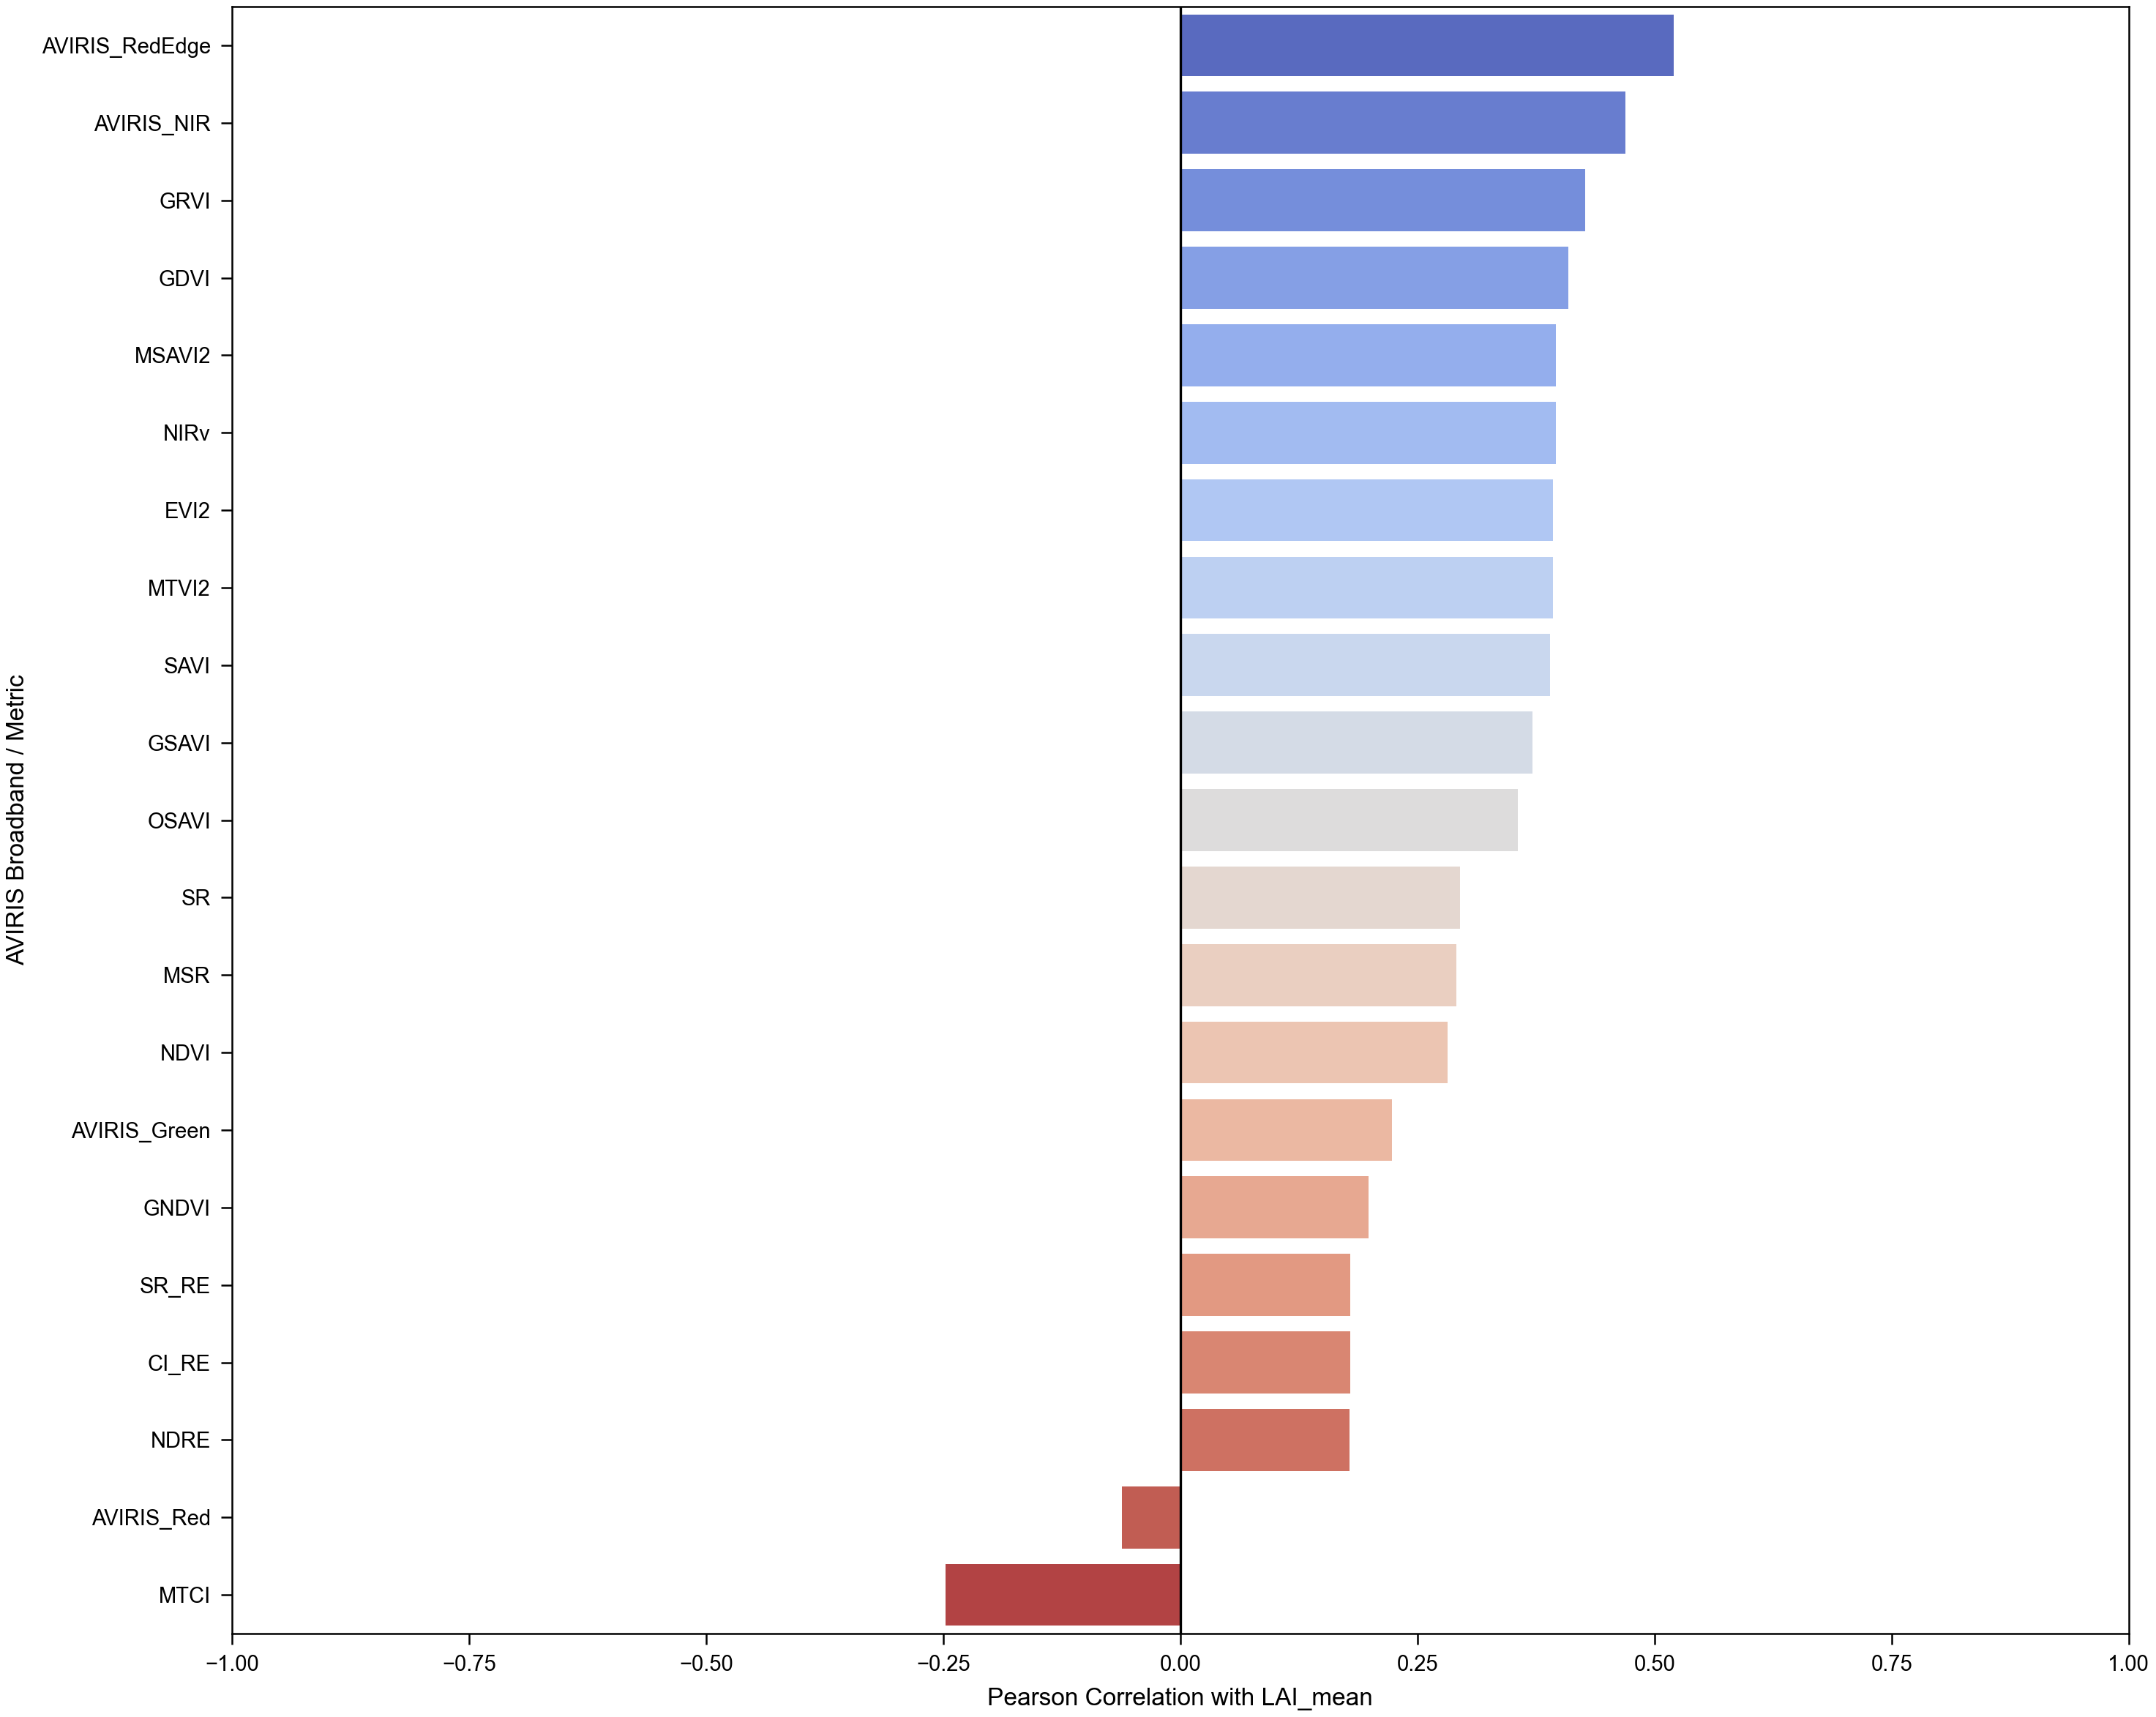

Running In-Sample Multi-Model Optimization...

--- IN-SAMPLE LEADERBOARD (TOP 10) ---
Rank  | Index    | Model Type   | R²     | RMSE   | AICc   | P-value
---------------------------------------------------------------------------
#1    | GRVI     | Quadratic    | 0.187  | 0.463  | -23.32 | 0.0568
#2    | GRVI     | Linear       | 0.182  | 0.464  | -26.00 | 0.0603
#3    | GDVI     | Quadratic    | 0.167  | 0.468  | -22.84 | 0.0732
#4    | GDVI     | Linear       | 0.167  | 0.468  | -25.63 | 0.0734
#5    | MSAVI2   | Quadratic    | 0.157  | 0.471  | -22.59 | 0.0837
#6    | MSAVI2   | Linear       | 0.157  | 0.471  | -25.39 | 0.0837
#7    | NIRv     | Quadratic    | 0.157  | 0.471  | -22.59 | 0.0841
#8    | NIRv     | Linear       | 0.157  | 0.471  | -25.38 | 0.0841
#9    | EVI2     | Quadratic    | 0.154  | 0.472  | -22.53 | 0.0865
#10   | EVI2     | Linear       | 0.154  | 0.472  | -25.33 | 0.0866
#11   | MTVI2    | Quadratic    | 0.154  | 0.472  | -22.53 | 0.0867
#12   | MTVI2    | Li

In [52]:
## C7. Performance analysis of AVIRIS-NG derived broadband metrics for LAI modeling.

print("Direct AVIRIS Broadbands based LAI Modeling:\n")

# Helper function for AICc
def compute_aicc(n, rss, k):
    aic = n * np.log(max(rss, 1e-10) / n) + 2 * k
    return aic + (2 * k * (k + 1)) / (n - k - 1)

def power_func(x, a, b):
    return a * np.power(x, b)

# Extract AVIRIS broadbands
G = aviris_modeling_df['AVIRIS_Green']
R = aviris_modeling_df['AVIRIS_Red']
RE = aviris_modeling_df['AVIRIS_RedEdge']
NIR = aviris_modeling_df['AVIRIS_NIR']

y_actual = aviris_modeling_df['LAI_mean'].values
n_samples = len(y_actual)

## 1. Standard / Broad-band Indices
aviris_modeling_df['NDVI'] = (NIR - R) / (NIR + R)
aviris_modeling_df['SR'] = NIR / R
aviris_modeling_df['GNDVI'] = (NIR - G) / (NIR + G)
aviris_modeling_df['GRVI'] = (G - R) / (G + R)
aviris_modeling_df['GDVI'] = NIR - G

## 2. Soil-Adjusted Indices
aviris_modeling_df['SAVI'] = ((NIR - R) / (NIR + R + 0.5)) * 1.5
aviris_modeling_df['GSAVI'] = ((NIR - G) / (NIR + G + 0.5)) * 1.5
aviris_modeling_df['OSAVI'] = ((NIR - R) / (NIR + R + 0.16)) * 1.16
aviris_modeling_df['MSAVI2'] = 0.5 * (2 * NIR + 1 - np.sqrt((2 * NIR + 1)**2 - 8 * (NIR - R)))

## 3. Red-Edge Indices
aviris_modeling_df['NDRE'] = (NIR - RE) / (NIR + RE)
aviris_modeling_df['SR_RE'] = NIR / RE
aviris_modeling_df['CI_RE'] = (NIR / RE) - 1
aviris_modeling_df['MTCI'] = (NIR - RE) / (RE - R)

## 4. Complex / Non-linear Indices
aviris_modeling_df['MSR'] = ((NIR / R) - 1) / (np.sqrt(NIR / R) + 1)
aviris_modeling_df['EVI2'] = 2.5 * (NIR - R) / (NIR + 2.4 * R + 1)
aviris_modeling_df['NIRv'] = aviris_modeling_df['NDVI'] * NIR
aviris_modeling_df['MTVI2'] = (
    1.5 * (1.2 * (NIR - G) - 2.5 * (R - G))
) / (
    np.sqrt((2 * NIR + 1)**2 - (6 * NIR - 5 * np.sqrt(R)) - 0.5)
)

indices_to_test = [
    'NDVI', 'SR', 'GNDVI', 'GRVI', 'GDVI',
    'SAVI', 'GSAVI', 'OSAVI', 'MSAVI2',
    'NDRE', 'SR_RE', 'CI_RE', 'MTCI',
    'MSR', 'EVI2', 'NIRv', 'MTVI2'
]

# Clean invalid values caused by division or square-root issues
aviris_modeling_df[indices_to_test] = (
    aviris_modeling_df[indices_to_test]
    .replace([np.inf, -np.inf], np.nan)
)

## Plot correlation of each AVIRIS broadband + derived metric with LAI_mean

aviris_bands_to_test = [
    'AVIRIS_Green',
    'AVIRIS_Red',
    'AVIRIS_RedEdge',
    'AVIRIS_NIR'
]

aviris_metrics_to_test = aviris_bands_to_test + indices_to_test

aviris_lai_correlations = (
    aviris_modeling_df[aviris_metrics_to_test + ['LAI_mean']]
    .corr(numeric_only=True)['LAI_mean']
    .drop('LAI_mean')
    .sort_values(ascending=False)
)

print("Correlation of each AVIRIS broadband and derived metric with LAI_mean:")
print(aviris_lai_correlations)

plt.figure(figsize=(10, 8))

sns.barplot(
    x=aviris_lai_correlations.values,
    y=aviris_lai_correlations.index,
    hue=aviris_lai_correlations.index,
    palette='coolwarm',
    legend=False
)

plt.axvline(0, color='black', linewidth=0.8)
plt.xlabel("Pearson Correlation with LAI_mean")
plt.ylabel("AVIRIS Broadband / Metric")
plt.xlim(-1, 1)
plt.tight_layout()
plt.show()

## Testing multiple functional forms for each index to find the best fit in-sample.
print("Running In-Sample Multi-Model Optimization...")
standard_results = []

for idx in indices_to_test:
    valid_mask = np.isfinite(aviris_modeling_df[idx].values) & np.isfinite(y_actual)
    x_val = aviris_modeling_df.loc[valid_mask, idx].values
    y_val = y_actual[valid_mask]

    if len(y_val) < 5:
        continue

    # Linear (k=2)
    p_lin = np.polyfit(x_val, y_val, 1)
    pred_lin = np.polyval(p_lin, x_val)
    rss_lin = np.sum((y_val - pred_lin)**2)
    standard_results.append({
        'Index': idx,
        'Model': 'Linear',
        'R2': r2_score(y_val, pred_lin),
        'RMSE': np.sqrt(mean_squared_error(y_val, pred_lin)),
        'AICc': compute_aicc(len(y_val), rss_lin, 2),
        'p_val': pearsonr(y_val, pred_lin)[1]
    })

    # Quadratic (k=3)
    p_quad = np.polyfit(x_val, y_val, 2)
    pred_quad = np.polyval(p_quad, x_val)
    rss_quad = np.sum((y_val - pred_quad)**2)
    standard_results.append({
        'Index': idx,
        'Model': 'Quadratic',
        'R2': r2_score(y_val, pred_quad),
        'RMSE': np.sqrt(mean_squared_error(y_val, pred_quad)),
        'AICc': compute_aicc(len(y_val), rss_quad, 3),
        'p_val': pearsonr(y_val, pred_quad)[1]
    })

standard_results.sort(key=lambda x: x['R2'], reverse=True)

print("\n--- IN-SAMPLE LEADERBOARD (TOP 10) ---")
print(f"{'Rank':<5} | {'Index':<8} | {'Model Type':<12} | {'R²':<6} | {'RMSE':<6} | {'AICc':<6} | {'P-value':<7}")
print("-" * 75)

for i, res in enumerate(standard_results[:]):
    print(f"#{i+1:<4} | {res['Index']:<8} | {res['Model']:<12} | {res['R2']:.3f}  | {res['RMSE']:.3f}  | {res['AICc']:<6.2f} | {res['p_val']:.4f}")

## LOOCV test for the top indices/models to get a true out-of-sample performance estimate.
print("\nRunning Leave-One-Out Cross-Validation (LOOCV)...")
loo = LeaveOneOut()
loocv_results = []

for idx in indices_to_test:
    valid_mask = np.isfinite(aviris_modeling_df[idx].values) & np.isfinite(y_actual)
    x_val = aviris_modeling_df.loc[valid_mask, idx].values
    y_val = y_actual[valid_mask]

    if len(y_val) < 5:
        continue

    preds_lin = np.zeros(len(x_val))
    preds_quad = np.zeros(len(x_val))
    preds_log = np.zeros(len(x_val))
    preds_pow = np.zeros(len(x_val))

    valid_log = np.all(x_val > 0)
    pow_failed = False

    for train_index, test_index in loo.split(x_val):
        x_train, x_test = x_val[train_index], x_val[test_index]
        y_train, y_test = y_val[train_index], y_val[test_index]

        preds_lin[test_index] = np.polyval(np.polyfit(x_train, y_train, 1), x_test)
        preds_quad[test_index] = np.polyval(np.polyfit(x_train, y_train, 2), x_test)

        if valid_log:
            p_log = np.polyfit(np.log(x_train), y_train, 1)
            preds_log[test_index] = p_log[0] * np.log(x_test) + p_log[1]

        if valid_log and not pow_failed:
            try:
                popt, _ = curve_fit(power_func, x_train, y_train, p0=[1, 1], maxfev=10000)
                preds_pow[test_index] = power_func(x_test, *popt)
            except:
                pow_failed = True

    loocv_results.append({
        'Index': idx,
        'Model': 'Linear',
        'LOOCV_R2': r2_score(y_val, preds_lin),
        'LOOCV_RMSE': np.sqrt(mean_squared_error(y_val, preds_lin))
    })

    loocv_results.append({
        'Index': idx,
        'Model': 'Quadratic',
        'LOOCV_R2': r2_score(y_val, preds_quad),
        'LOOCV_RMSE': np.sqrt(mean_squared_error(y_val, preds_quad))
    })

loocv_results.sort(key=lambda x: x['LOOCV_R2'], reverse=True)

print("\n--- OUT-OF-SAMPLE LOOCV LEADERBOARD (TOP 10) ---")
print(f"{'Rank':<5} | {'Index':<8} | {'Model Type':<12} | {'LOOCV R²':<8} | {'LOOCV RMSE':<8}")
print("-" * 55)

for i, res in enumerate(loocv_results[:]):
    print(f"#{i+1:<4} | {res['Index']:<8} | {res['Model']:<12} | {res['LOOCV_R2']:<8.3f} | {res['LOOCV_RMSE']:<8.3f}")

print("-"*100)
print(f" " * 25 + "Section B-AVIRIS sampled broadband data analysis completed!!")
print("-"*100)

In [53]:
"""
D. Now we are using drone-based rasters to harmonize the AVIRIS-NG broadband data for better LAI modeling. 
   - We divide the drone rasters into continuous 5mx5m grid cells and extract the mean reflectance for each cell.
   - And then we will use these 5mx5m grid cells to extract the corresponding AVIRIS-NG spectra and try to harmonize 
   the AVIRIS-NG broadband data to the drone data for better LAI modeling.
   - RF based harmonization
"""

## D1. Use full drone rasters to harmonize the AVIRIS based reflectance data.

# Drone rasters file paths
file_map = {
    "BY_2006": "./Drone_msi_data/burn2006_lr_band_stack.tif",
    "BY_2016": "./Drone_msi_data/burn2016_lr_band_stack.tif",
    "BY_2019": "./Drone_msi_data/burn2019_lr_band_stack.tif",
    "BY_2020": "./Drone_msi_data/burn2020_lr_band_stack.tif",
    "BY_2017_16": "./Drone_msi_data/burn2017_2016_lr_band_stack.tif"
}

grid_size_m = 5.0 # Exactly 5x5 meter grid cells

virtual_plots = []
plot_id_counter = 1

print("--- Phase C1: Continuous 5x5m Fishnet Extraction ---")

drone_crs = None 

for site, path in file_map.items():
    print(f"\nProcessing {site}...")
    with rasterio.open(path) as src:
        if drone_crs is None: drone_crs = src.crs
            
        bounds = src.bounds
        valid_grids = 0
        rejected_nodata = 0
        
        # Generate the coordinates for the 5m grid lines
        x_coords = np.arange(bounds.left, bounds.right, grid_size_m)
        y_coords = np.arange(bounds.bottom, bounds.top, grid_size_m)
        
        # March through every single 5x5m cell in the grid
        for x, y in itertools.product(x_coords[:-1], y_coords[:-1]):
            
            # Define the physical boundaries of this 5x5m cell
            left, bottom = x, y
            right, top = x + grid_size_m, y + grid_size_m
            
            try:
                # Convert the physical coordinates to pixel rows/cols
                row_start, col_start = src.index(left, top)
                row_stop, col_stop = src.index(right, bottom)
                
                # Extract the chunk of pixels for this 5x5m box
                win = rasterio.windows.Window.from_slices((row_start, row_stop), (col_start, col_stop))
                data = src.read(window=win)
                
                # Skip if the window is empty (edge of map)
                if data.size == 0:
                    continue
                    
                # STRICT VALIDITY CHECK: No NoData or negative values allowed
                if np.all(data > 0) and not np.isnan(data).any():
                    
                    # We store the CENTROID of the grid cell as our geometry point
                    # This makes it super easy to extract AVIRIS data in Phase 2
                    centroid_x = left + (grid_size_m / 2)
                    centroid_y = bottom + (grid_size_m / 2)
                    
                    virtual_plots.append({
                        'plot_id': f"{site}_Grid_{valid_grids+1}",
                        'geometry': Point(centroid_x, centroid_y),
                        'Drone_G': np.mean(data[0]),
                        'Drone_R': np.mean(data[1]),
                        'Drone_RE': np.mean(data[2]),
                        'Drone_NIR': np.mean(data[3]),
                        'site': site
                    })
                    valid_grids += 1
                else:
                    rejected_nodata += 1
                    
            except Exception:
                pass # Ignores edge cases that fall outside the raster

        print(f"  -> Valid 5x5m Grids Extracted: {valid_grids}")
        print(f"  -> Grids Rejected (Hit NoData/Map Edge): {rejected_nodata}")

if not virtual_plots:
    print("\nCRITICAL ERROR: No grids were extracted.")
else:
    gdf_virtual = gpd.GeoDataFrame(virtual_plots, crs=drone_crs, geometry='geometry')
    print(f"\nPhase 1 Complete: {len(gdf_virtual)} continuous grid plots created.\n")

--- Phase C1: Continuous 5x5m Fishnet Extraction ---

Processing BY_2006...
  -> Valid 5x5m Grids Extracted: 973
  -> Grids Rejected (Hit NoData/Map Edge): 357

Processing BY_2016...
  -> Valid 5x5m Grids Extracted: 758
  -> Grids Rejected (Hit NoData/Map Edge): 262

Processing BY_2019...
  -> Valid 5x5m Grids Extracted: 680
  -> Grids Rejected (Hit NoData/Map Edge): 248

Processing BY_2020...
  -> Valid 5x5m Grids Extracted: 529
  -> Grids Rejected (Hit NoData/Map Edge): 254

Processing BY_2017_16...
  -> Valid 5x5m Grids Extracted: 746
  -> Grids Rejected (Hit NoData/Map Edge): 308

Phase 1 Complete: 3686 continuous grid plots created.



In [54]:
## Print the virtual plots GeoDataFrame 

gdf_virtual

,plot_id,geometry,Drone_G,Drone_R,Drone_RE,Drone_NIR,site
0,BY_2006_Grid_1,POINT (354676.987 6177732.648),0.009578,0.009522,0.024264,0.209286,BY_2006
1,BY_2006_Grid_2,POINT (354676.987 6177737.648),0.009242,0.009064,0.023692,0.209415,BY_2006
2,BY_2006_Grid_3,POINT (354676.987 6177742.648),0.009129,0.008720,0.024258,0.219495,BY_2006
3,BY_2006_Grid_4,POINT (354676.987 6177747.648),0.009773,0.008690,0.025837,0.240279,BY_2006
4,BY_2006_Grid_5,POINT (354676.987 6177752.648),0.010561,0.009614,0.027558,0.252923,BY_2006
...,...,...,...,...,...,...,...
3681,BY_2017_16_Grid_742,POINT (356074.391 6178694.461),0.015384,0.011789,0.052269,0.234897,BY_2017_16
3682,BY_2017_16_Grid_743,POINT (356074.391 6178699.461),0.015425,0.012533,0.053381,0.225844,BY_2017_16
3683,BY_2017_16_Grid_744,POINT (356074.391 6178704.461),0.013879,0.010210,0.050183,0.244019,BY_2017_16
3684,BY_2017_16_Grid_745,POINT (356074.391 6178709.461),0.015486,0.014583,0.048382,0.204231,BY_2017_16


In [55]:
## D2. Extract AVIRIS-NG spectra at the virtual plot locations.

print(f"--- Phase D2: Extracting AVIRIS Spectra for {len(gdf_virtual)} virtual plots ---")

# We use the virtual GeoDataFrame
candidates = {pid: [] for pid in gdf_virtual['plot_id'].unique()}
wavelengths = None

# Main loop through AVIRIS raster files
for nc_file in raster_files: # 'raster_files' is defined earlier in the notebook
    actual_path = nc_file if os.path.exists(nc_file) else os.path.basename(nc_file)
    if not os.path.exists(actual_path): continue

    netcdf_path = f"NETCDF:{actual_path}:/reflectance/reflectance"

    try:
        with rasterio.open(netcdf_path) as src:
            if wavelengths is None:
                with Dataset(actual_path, mode="r") as ds:
                    wavelengths = ds.groups["reflectance"].variables["wavelength"][:]

            # Project our drone grids to match AVIRIS CRS
            gdf_local = gdf_virtual.to_crs(src.crs)

            # Pre-calculate flightline bounds to speed up the loop
            flightline_box = box(src.bounds.left, src.bounds.bottom, src.bounds.right, src.bounds.top)

            for idx, row in gdf_local.iterrows():
                geom = row.geometry
                cx, cy = geom.x, geom.y # geom is already the Point centroid from Phase 1
                
                # Check if point is actually inside this flightline
                if not flightline_box.contains(geom):
                    continue

                try:
                    r, c = src.index(cx, cy)
                    
                    # Ensure the calculated row/col is within the image bounds
                    if 0 <= r < src.height and 0 <= c < src.width:
                        
                        # We extract exactly 1 pixel at column 'c' and row 'r'
                        window = rasterio.windows.Window(c, r, 1, 1)
                        data_2d = src.read(window=window) 
                        
                        # Flatten the spatial dimensions: shape becomes (bands, 1)
                        data_2d = data_2d.reshape(src.count, -1)
                        
                        # Check validity (band 100 > -50 logic)
                        if data_2d[100, 0] > -50: 
                            
                            # Since it's exactly 1 pixel, the "mean" is just the pixel's spectrum
                            spectrum = data_2d[:, 0]
                            
                            # Nadir-selection logic
                            img_cx = (src.bounds.left + src.bounds.right) / 2
                            img_cy = (src.bounds.top + src.bounds.bottom) / 2
                            dist = np.sqrt((cx - img_cx)**2 + (cy - img_cy)**2)
                            
                            candidates[row['plot_id']].append({
                                'spectrum': spectrum,
                                'dist': dist,
                                'file': os.path.basename(actual_path)
                            })
                except Exception:
                    continue
    except Exception as e:
        print(f"  [ERROR] {os.path.basename(actual_path)}: {e}")

# Finalize AVIRIS records
final_aviris_records = []
for pid, data_list in candidates.items():
    if not data_list: continue # Skip points that didn't land in any valid AVIRIS pixel
    
    # Sort by closest to center of flightline (Nadir)
    data_list.sort(key=lambda x: x['dist']) 
    best = data_list[0]
    
    rec = {'plot_id': pid}
    for i, val in enumerate(best['spectrum']):
        rec[f'band_{i}'] = val
    final_aviris_records.append(rec)

df_aviris = pd.DataFrame(final_aviris_records)

# Phase 3: Merge Drone Data and AVIRIS Data together
big_dataset = pd.merge(gdf_virtual.drop(columns='geometry'), df_aviris, on='plot_id', how='inner')
print(f"\nExtraction Complete! We have {len(big_dataset)} perfectly matched points ready for modeling.")

--- Phase D2: Extracting AVIRIS Spectra for 3686 virtual plots ---

Extraction Complete! We have 3686 perfectly matched points ready for modeling.


In [56]:
# The combined dataset

big_dataset

,plot_id,Drone_G,Drone_R,Drone_RE,Drone_NIR,site,band_0,band_1,band_2,band_3,...,band_415,band_416,band_417,band_418,band_419,band_420,band_421,band_422,band_423,band_424
0,BY_2006_Grid_1,0.009578,0.009522,0.024264,0.209286,BY_2006,-0.008550,0.004086,0.009241,0.014136,...,0.039741,0.041741,0.041818,0.039615,0.041396,0.043607,0.043289,0.045638,0.046564,0.048033
1,BY_2006_Grid_2,0.009242,0.009064,0.023692,0.209415,BY_2006,-0.008707,-0.002167,0.011510,0.010081,...,0.041350,0.044974,0.037250,0.038626,0.043537,0.037844,0.041782,0.042854,0.043037,0.046161
2,BY_2006_Grid_3,0.009129,0.008720,0.024258,0.219495,BY_2006,-0.005061,-0.001383,0.008843,0.008975,...,0.035286,0.036688,0.033422,0.039104,0.037310,0.036591,0.034981,0.033712,0.031928,0.049430
3,BY_2006_Grid_4,0.009773,0.008690,0.025837,0.240279,BY_2006,-0.010118,0.004567,0.007268,0.010145,...,0.041448,0.042082,0.044694,0.046681,0.047748,0.050870,0.052161,0.053766,0.055090,0.054992
4,BY_2006_Grid_5,0.010561,0.009614,0.027558,0.252923,BY_2006,-0.010118,0.004567,0.007268,0.010145,...,0.041448,0.042082,0.044694,0.046681,0.047748,0.050870,0.052161,0.053766,0.055090,0.054992
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3681,BY_2017_16_Grid_742,0.015384,0.011789,0.052269,0.234897,BY_2017_16,-0.013867,-0.004608,0.000728,0.006079,...,0.034943,0.034131,0.037351,0.044858,0.053149,0.061657,0.069387,0.076704,0.084375,0.147091
3682,BY_2017_16_Grid_743,0.015425,0.012533,0.053381,0.225844,BY_2017_16,-0.013867,-0.004608,0.000728,0.006079,...,0.034943,0.034131,0.037351,0.044858,0.053149,0.061657,0.069387,0.076704,0.084375,0.147091
3683,BY_2017_16_Grid_744,0.013879,0.010210,0.050183,0.244019,BY_2017_16,-0.021484,-0.001960,0.004939,0.009909,...,0.074733,0.072331,0.065658,0.071157,0.081051,0.099459,0.115853,0.130477,0.145695,0.162140
3684,BY_2017_16_Grid_745,0.015486,0.014583,0.048382,0.204231,BY_2017_16,-0.016320,-0.008012,0.005250,0.010062,...,0.073868,0.077619,0.074359,0.082218,0.089694,0.103536,0.114065,0.124978,0.136117,0.147070


In [57]:
## D3. Simulate DJI Mavic 3M MSI bands for virtual plots using rectangular bandpass averaging

print("--- Phase D3: Rectangular-bandpass AVIRIS-to-DJI MSI resampling for virtual plots ---")

for band_name, specs in drone_bands.items():
    min_wl = specs["center"] - specs["tolerance"]
    max_wl = specs["center"] + specs["tolerance"]

    indices = np.where((wavelengths >= min_wl) & (wavelengths <= max_wl))[0]
    band_cols = [f"band_{i}" for i in indices]

    big_dataset[f"AVIRIS_{band_name}"] = big_dataset[band_cols].mean(axis=1)

    print(
        f"{band_name}: averaged {len(indices)} AVIRIS-NG bands "
        f"between {wavelengths[indices[0]]:.1f} and {wavelengths[indices[-1]]:.1f} nm"
    )

display(big_dataset[["AVIRIS_Green", "AVIRIS_Red", "AVIRIS_RedEdge", "AVIRIS_NIR"]].describe())

--- Phase D3: Rectangular-bandpass AVIRIS-to-DJI MSI resampling for virtual plots ---
Green: averaged 6 AVIRIS-NG bands between 547.5 and 572.5 nm
Red: averaged 6 AVIRIS-NG bands between 637.6 and 662.7 nm
RedEdge: averaged 6 AVIRIS-NG bands between 717.8 and 742.8 nm
NIR: averaged 10 AVIRIS-NG bands between 838.0 and 883.1 nm


,AVIRIS_Green,AVIRIS_Red,AVIRIS_RedEdge,AVIRIS_NIR
count,3686.000000,3686.000000,3686.000000,3686.000000
mean,0.052101,0.048522,0.153185,0.227620
std,0.006779,0.009243,0.014389,0.022993
min,0.041072,0.033944,0.126833,0.182377
25%,0.048386,0.043920,0.143292,0.209959
50%,0.051140,0.047653,0.149996,0.223338
75%,0.053927,0.050988,0.160485,0.241720
max,0.133450,0.154648,0.264838,0.352497


In [58]:
# JUST FOR PLOTTING PURPOSES: Burn-year labels from AVIRIS plot_id

color_mapping = {
    "BY_2006": "#1f77b4",
    "BY_2016": "#2ca02c",
    "BY_2019": "#ff7f0e",
    "BY_2020": "#d62728",
}

dataset_order = ["BY_2006", "BY_2016", "BY_2019", "BY_2020"]


def burn_year_from_plot_id(plot_id):
    plot_id = str(plot_id)

    if plot_id.startswith("GBS06"):
        return "BY_2006"
    if plot_id.startswith("GBS16"):
        return "BY_2016"
    if plot_id.startswith("GBS19"):
        return "BY_2019"
    if plot_id.startswith("GBS20"):
        return "BY_2020"

    return "Unknown"


plot_data["dataset"] = plot_data["plot_id"].apply(burn_year_from_plot_id)

--- Phase 4: Machine Learning Cross-Sensor Band harmonization ---
Training Random Forest to harmonize Simulated Green to Drone Green...
Training Random Forest to harmonize Simulated Red to Drone Red...
Training Random Forest to harmonize Simulated RedEdge to Drone RedEdge...
Training Random Forest to harmonize Simulated NIR to Drone NIR...


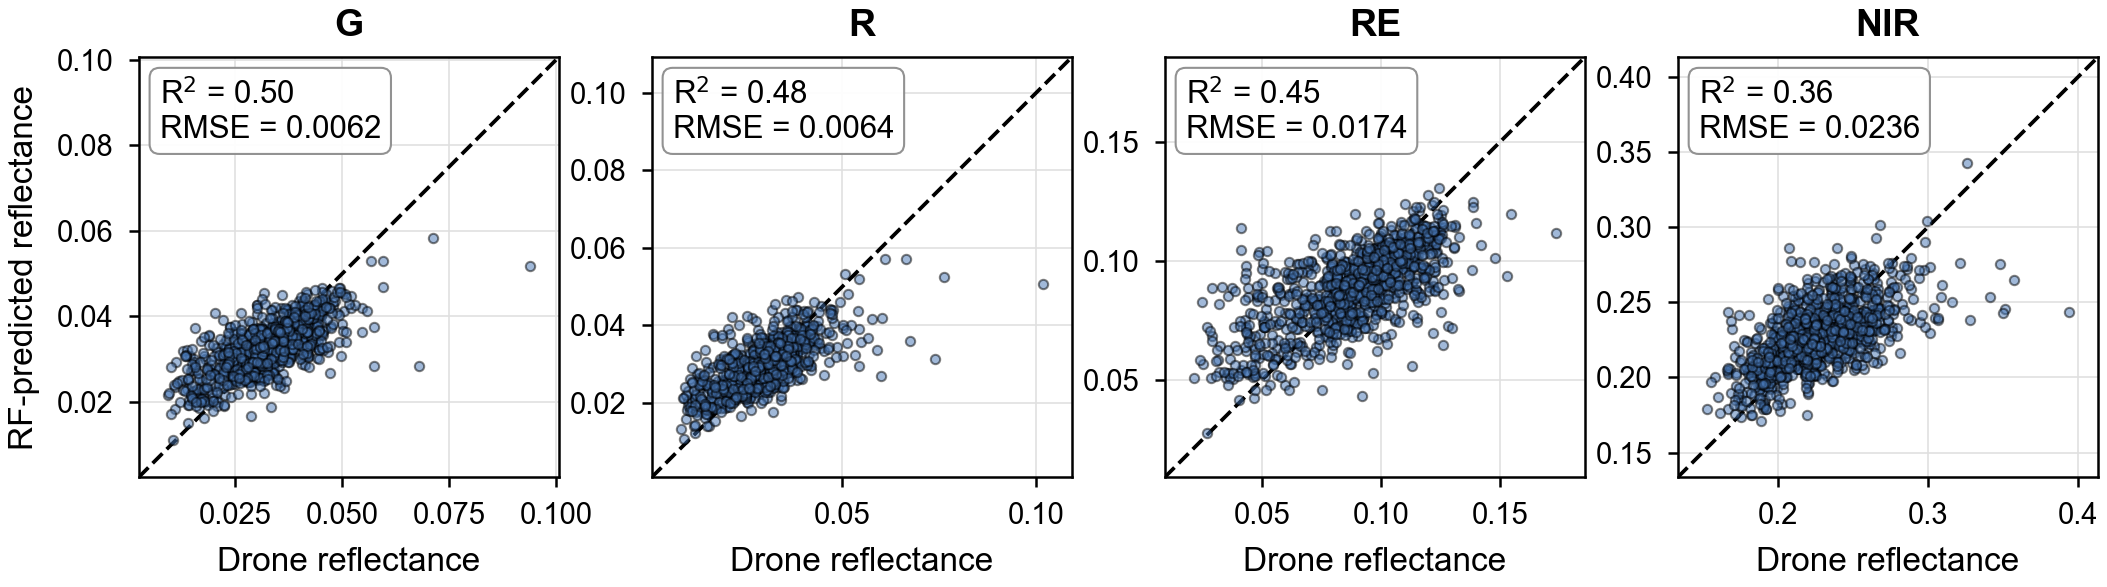


--- Random Forest Band harmonization Performance (Test Set) ---
Green   | R² = 0.50 | RMSE = 0.0062
Red     | R² = 0.48 | RMSE = 0.0064
RedEdge | R² = 0.45 | RMSE = 0.0174
NIR     | R² = 0.36 | RMSE = 0.0236

--- Phase 5: The Ultimate Multi-Index & Multi-Model Optimization ---
harmonrating the 4 simulated broadbands to drone-equivalents via RF...
Calculating 17 Vegetation Indices...

--- THE ULTIMATE LAI harmonization LEADERBOARD ---
Rank  | Index    | Model Type   | R²     | RMSE   | AICc   | P-value
---------------------------------------------------------------------------
#1    | GNDVI    | Quadratic    | 0.319  | 0.424  | -26.87 | 0.0095
#2    | GNDVI    | Linear       | 0.310  | 0.426  | -29.40 | 0.0107
#3    | GSAVI    | Quadratic    | 0.289  | 0.433  | -26.00 | 0.0145
#4    | GSAVI    | Linear       | 0.269  | 0.439  | -28.23 | 0.0192
#5    | GDVI     | Quadratic    | 0.269  | 0.439  | -25.43 | 0.0192
#6    | GDVI     | Linear       | 0.233  | 0.449  | -27.28 | 0.0311
#7    | 

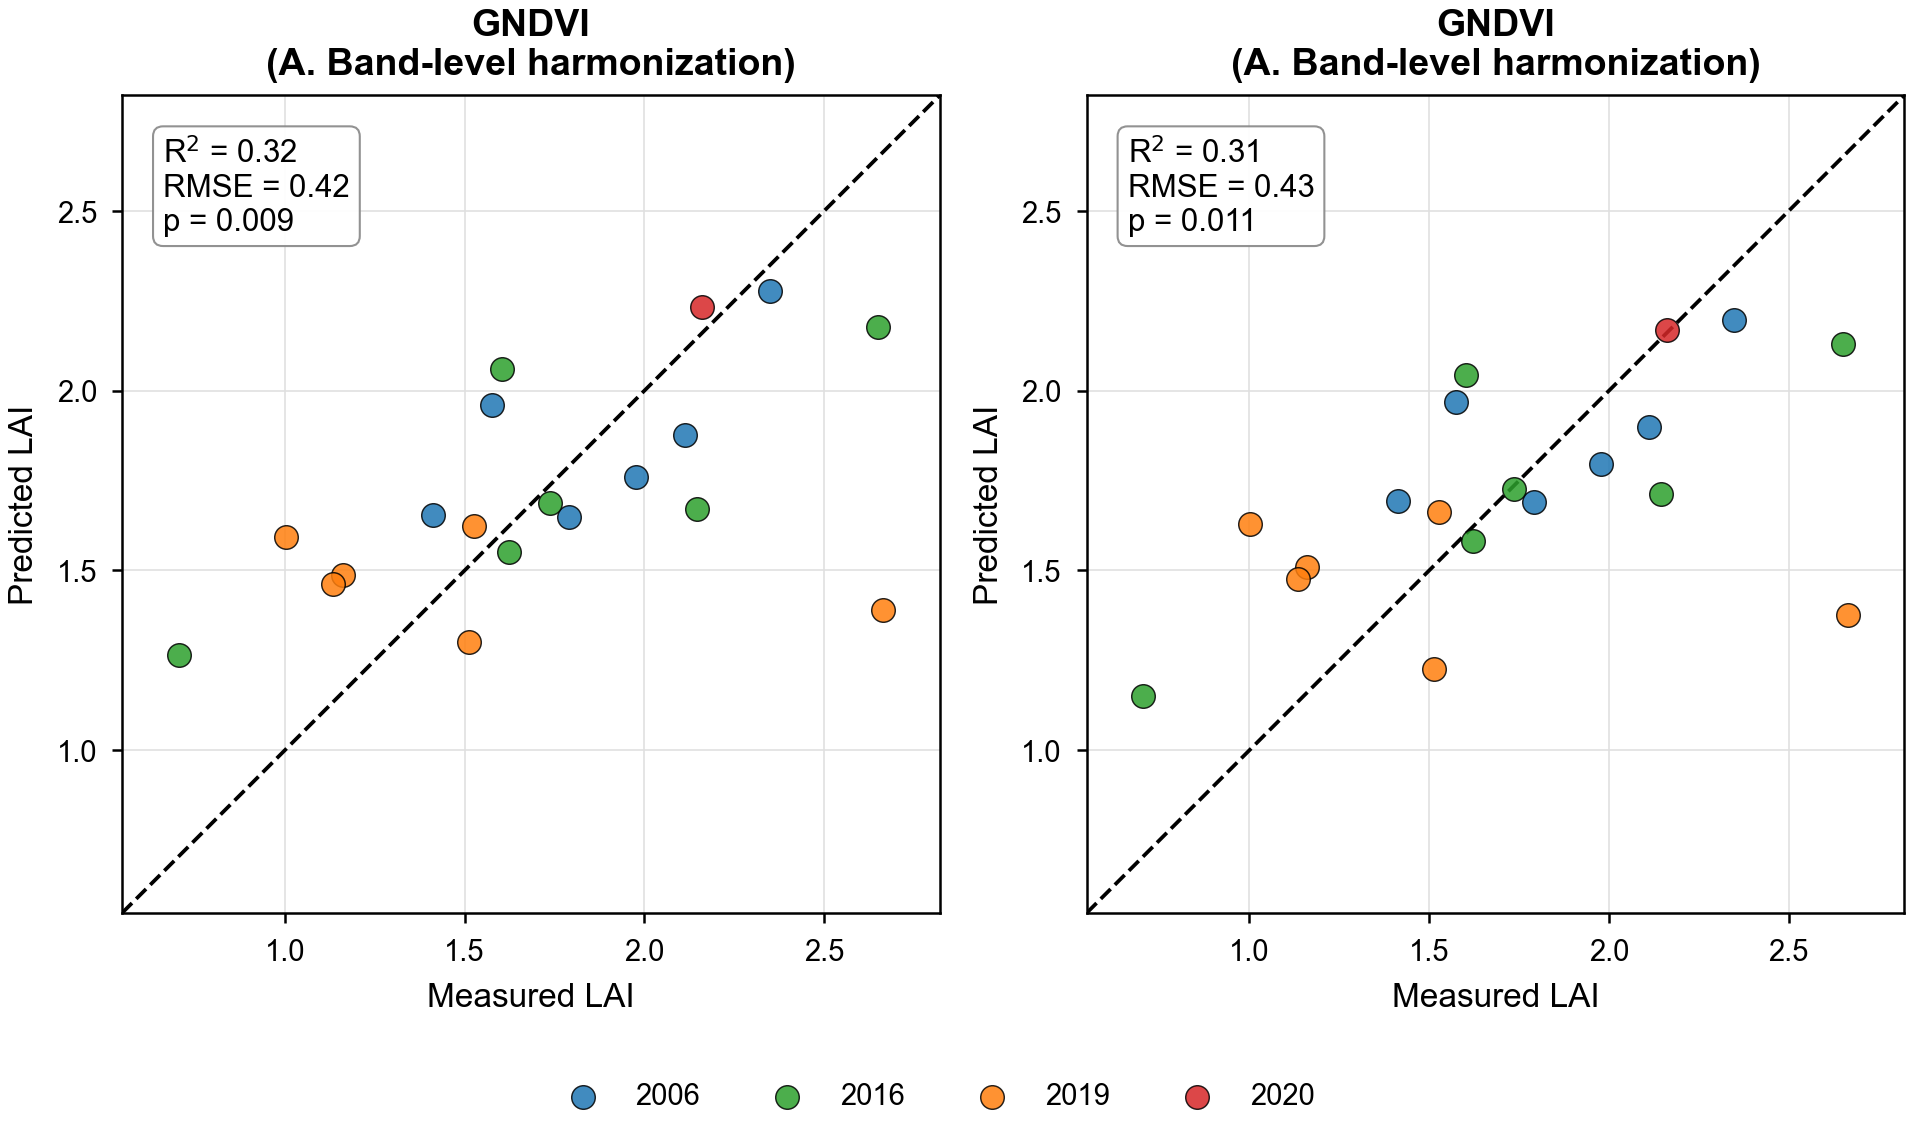

--- Phase 6: Robustness Testing via LOOCV ---

--- TRUE OUT-OF-SAMPLE LOOCV LEADERBOARD ---
Rank  | Index    | Model Type   | LOOCV R² | LOOCV RMSE
-------------------------------------------------------
#1    | GNDVI    | Linear       | 0.117    | 0.482   
#2    | GSAVI    | Linear       | 0.083    | 0.492   
#3    | GDVI     | Quadratic    | 0.063    | 0.497   
#4    | GSAVI    | Quadratic    | 0.062    | 0.497   
#5    | GDVI     | Linear       | 0.037    | 0.504   
#6    | MSAVI2   | Linear       | -0.004   | 0.514   
#7    | EVI2     | Linear       | -0.007   | 0.515   
#8    | SAVI     | Linear       | -0.008   | 0.515   
#9    | NIRv     | Linear       | -0.009   | 0.516   
#10   | OSAVI    | Linear       | -0.053   | 0.527   
#11   | SR_RE    | Linear       | -0.064   | 0.529   
#12   | CI_RE    | Linear       | -0.064   | 0.529   
#13   | GNDVI    | Quadratic    | -0.069   | 0.531   
#14   | MTCI     | Linear       | -0.073   | 0.532   
#15   | MTVI2    | Linear       | -0.094

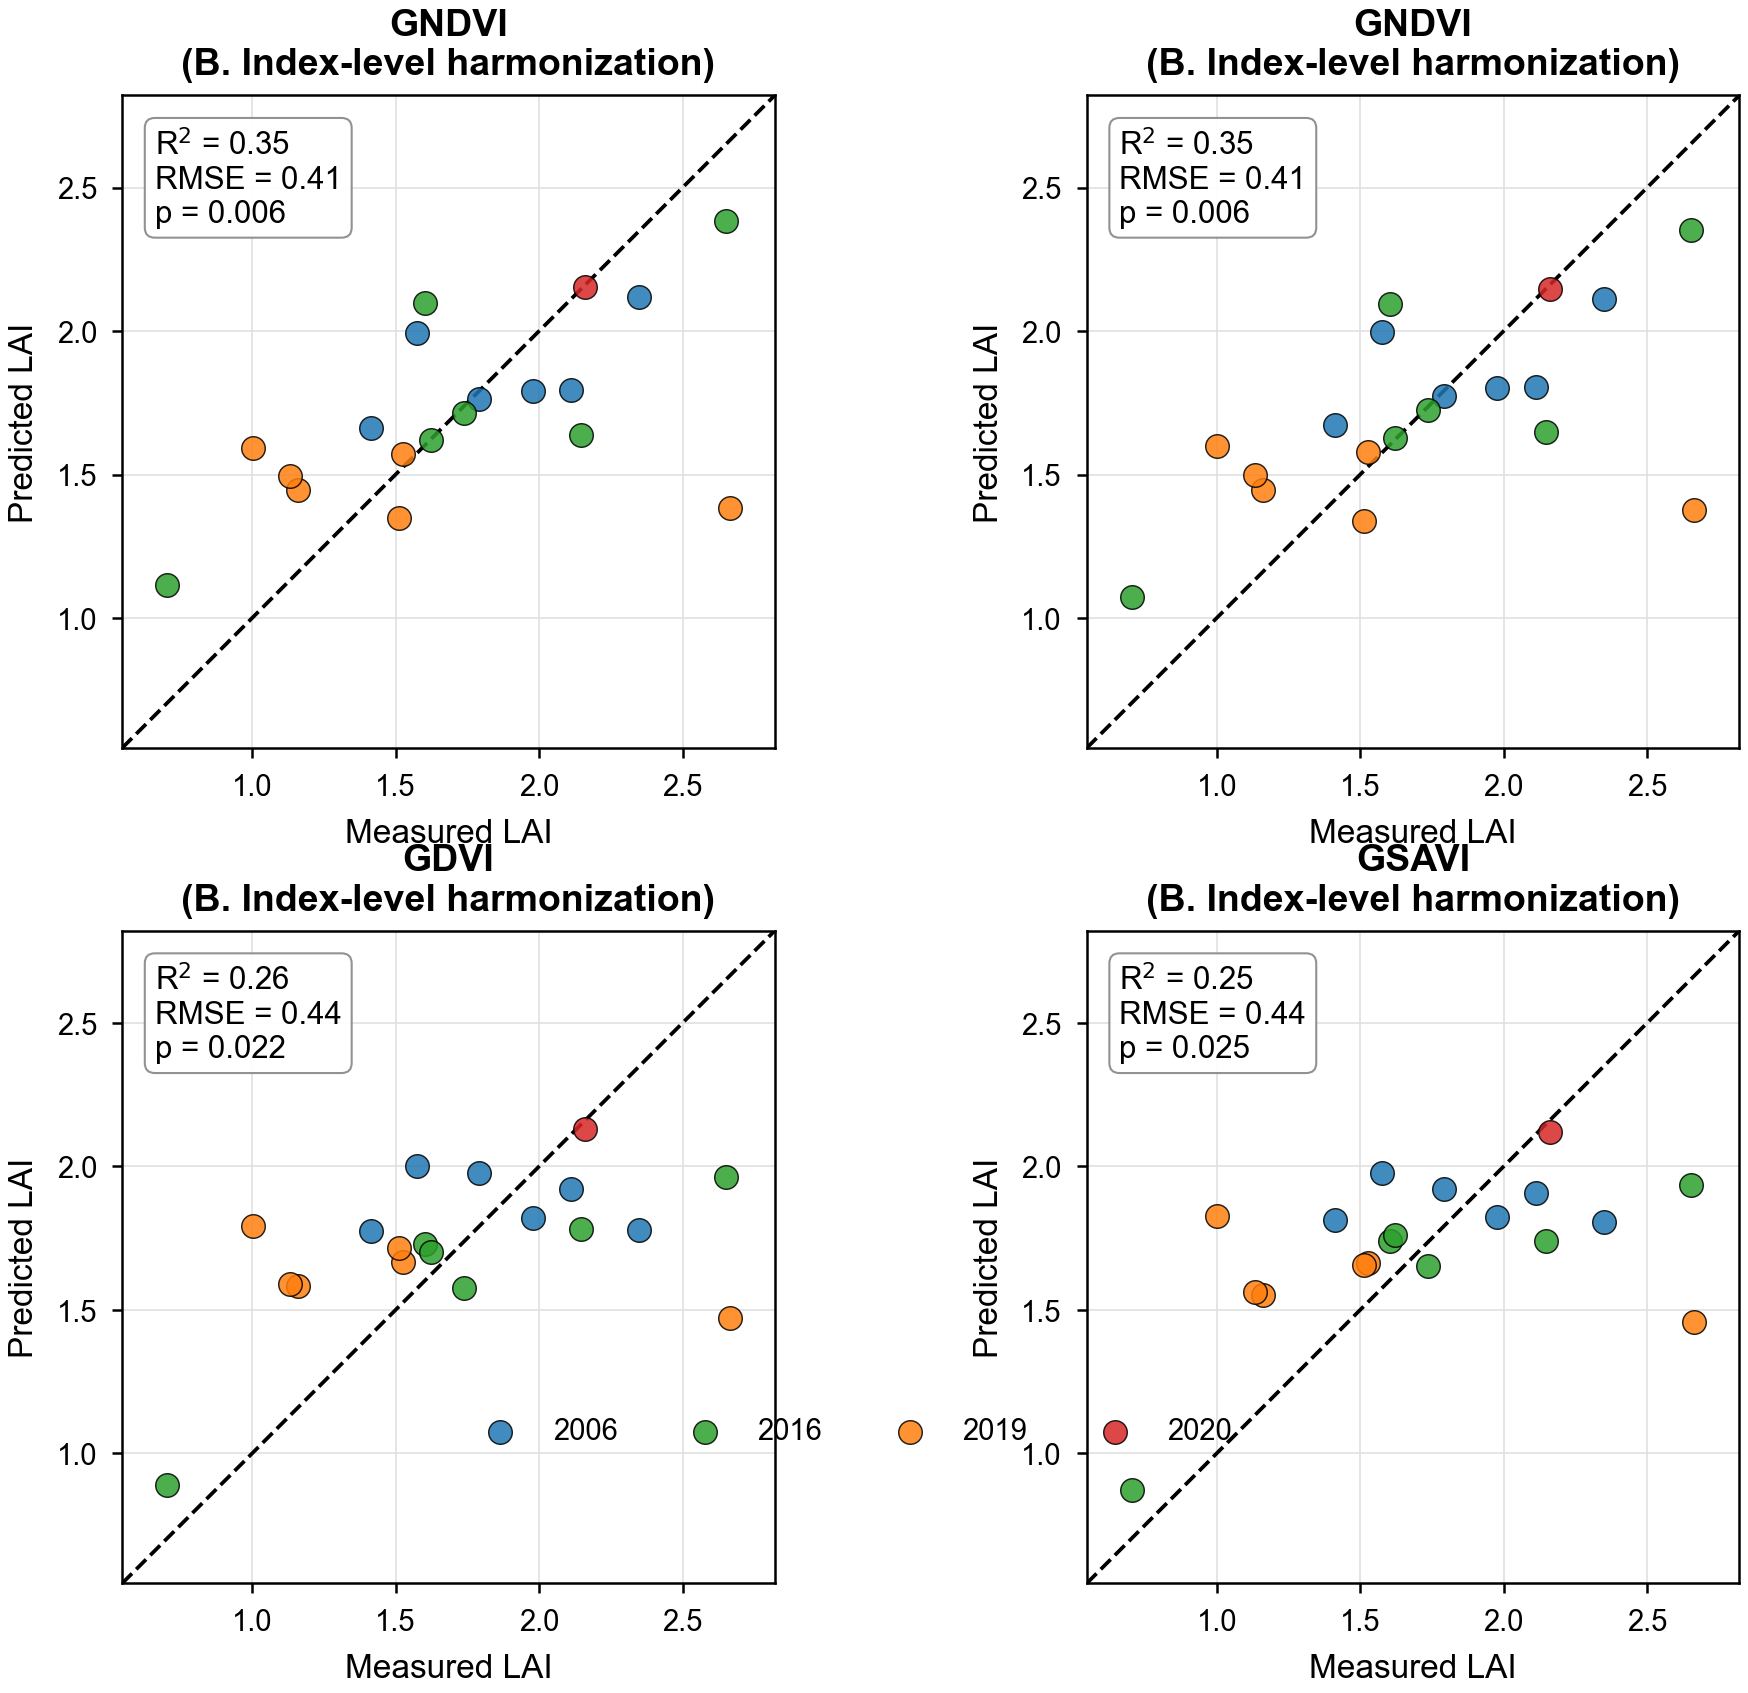


--- Phase 8: Leave-One-Out Cross Validation (LOOCV) for Direct Indices ---
Running strict LOOCV for all indices and mathematical models (N=20)...

--- THE STRICT LOOCV LAI LEADERBOARD ---
Rank  | Index    | Model Type   | LOOCV R² | LOOCV RMSE
-------------------------------------------------------
#1    | GNDVI    | Linear       |    0.173 |    0.467
#2    | GSAVI    | Linear       |    0.031 |    0.505
#3    | GDVI     | Quadratic    |    0.030 |    0.506
#4    | GDVI     | Linear       |    0.024 |    0.507
#5    | SR       | Linear       |   -0.004 |    0.514
#6    | NIRv     | Linear       |   -0.013 |    0.517
#7    | GSAVI    | Quadratic    |   -0.025 |    0.520
#8    | SAVI     | Linear       |   -0.027 |    0.520
#9    | NDRE     | Linear       |   -0.030 |    0.521
#10   | MSAVI2   | Linear       |   -0.036 |    0.522
#11   | GRVI     | Quadratic    |   -0.044 |    0.524
#12   | MTCI     | Linear       |   -0.049 |    0.526
#13   | OSAVI    | Linear       |   -0.050 |    0.5

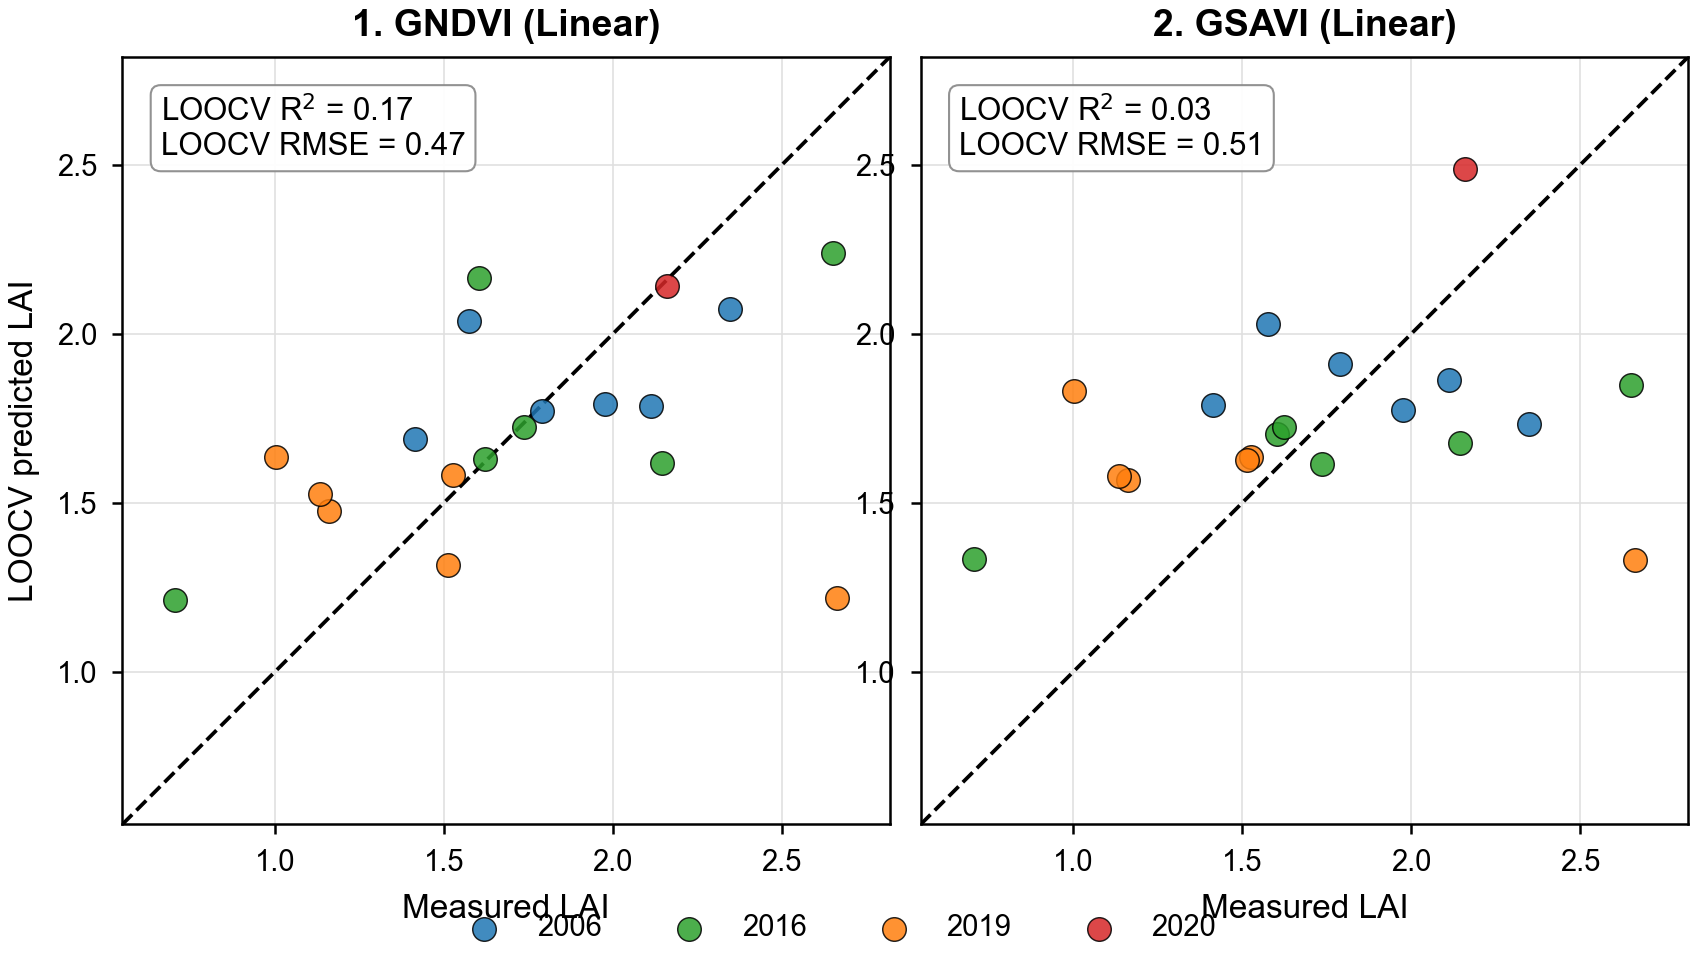

                         Section D-Drone based broadband AVIRIS harmonization and Analysis Completed!!


In [59]:
## D4. Map/harmonize aviris simulated broadbands to drone-bands using machine learning (Random Forest):

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.model_selection import LeaveOneOut

print("--- Phase 4: Machine Learning Cross-Sensor Band harmonization ---")

# Setup the plotting style

def format_1to1_axis(ax, min_val, max_val):
    ax.plot(
        [min_val, max_val],
        [min_val, max_val],
        color="black",
        linestyle="--",
        linewidth=0.9,
        zorder=1
    )
    ax.set_xlim(min_val, max_val)
    ax.set_ylim(min_val, max_val)
    ax.set_aspect("equal", adjustable="box")
    ax.grid(True, color="0.88", linewidth=0.4)
    ax.set_axisbelow(True)
    ax.tick_params(axis="both", length=2.5, width=0.6)

    for spine in ax.spines.values():
        spine.set_linewidth(0.6)


def add_stats_box(ax, text):
    ax.text(
        0.05,
        0.95,
        text,
        transform=ax.transAxes,
        va="top",
        ha="left",
        fontsize=7.5,
        linespacing=1.20,
        bbox={
            "boxstyle": "round,pad=0.32",
            "facecolor": "white",
            "edgecolor": "0.55",
            "linewidth": 0.5,
            "alpha": 0.95,
        }
    )

# 1. Define the targets we want to predict
drone_targets = {
    'Green': 'Drone_G',
    'Red': 'Drone_R',
    'RedEdge': 'Drone_RE',
    'NIR': 'Drone_NIR'
}

# 2. Prepare the Features (X)
simulated_msi_cols = ['AVIRIS_Green', 'AVIRIS_Red', 'AVIRIS_RedEdge', 'AVIRIS_NIR']

# Filter out physically impossible negative values to give the model clean data
clean_data = big_dataset[
    (big_dataset['Drone_G'] > 0) & (big_dataset['Drone_R'] > 0) & 
    (big_dataset['Drone_RE'] > 0) & (big_dataset['Drone_NIR'] > 0)
].copy()

X_full = clean_data[simulated_msi_cols]

# D4. RF cross-sensor band harmonization figure

fig, axes = plt.subplots(1, 4, figsize=(7.1, 2.15))

rf_models = {}
rf_metrics = {}

band_label_map = {
    "Green": "G",
    "Red": "R",
    "RedEdge": "RE",
    "NIR": "NIR",
}

for ax, (band_name, drone_col) in zip(axes, drone_targets.items()):
    print(f"Training Random Forest to harmonize Simulated {band_name} to Drone {band_name}...")

    y = clean_data[drone_col]

    X_train, X_test, y_train, y_test = train_test_split(
        X_full,
        y,
        test_size=0.30,
        random_state=42
    )

    rf = RandomForestRegressor(
        n_estimators=150,
        random_state=42,
        n_jobs=-1
    )

    rf.fit(X_train, y_train)
    y_pred_test = rf.predict(X_test)

    test_r2 = r2_score(y_test, y_pred_test)
    test_rmse = np.sqrt(mean_squared_error(y_test, y_pred_test))

    rf_models[band_name] = rf
    rf_metrics[band_name] = {
        "R2": test_r2,
        "RMSE": test_rmse
    }

    min_val = min(y_test.min(), y_pred_test.min())
    max_val = max(y_test.max(), y_pred_test.max())
    pad = 0.08 * (max_val - min_val)
    axis_min = min_val - pad
    axis_max = max_val + pad

    ax.scatter(
        y_test,
        y_pred_test,
        color="#4575b4",
        edgecolor="black",
        linewidth=0.5,
        s=5,
        alpha=0.5,
        zorder=2
    )

    format_1to1_axis(ax, axis_min, axis_max)

    stats_text = (
        f"R$^2$ = {test_r2:.2f}\n"
        f"RMSE = {test_rmse:.4f}"
    )
    add_stats_box(ax, stats_text)

    short_name = band_label_map.get(band_name, band_name)
    ax.set_title(short_name, fontweight="bold", pad=5)
    ax.set_xlabel("Drone reflectance")

axes[0].set_ylabel("RF-predicted reflectance")

fig.subplots_adjust(
    left=0.075,
    right=0.995,
    bottom=0.22,
    top=0.88,
    wspace=0.22
)
plt.show()

print("\n--- Random Forest Band harmonization Performance (Test Set) ---")
for band, metrics in rf_metrics.items():
    print(f"{band:7s} | R² = {metrics['R2']:.2f} | RMSE = {metrics['RMSE']:.4f}")

## D5. Testing the AVIRIS-NG derived broadband metrics for LAI modeling using the simulated drone bands 
# and comparing the performance of different vegetation indices LAI prediction.

print("\n--- Phase 5: The Ultimate Multi-Index & Multi-Model Optimization ---")

# Helper function for AICc
def compute_aicc(n, rss, k):
    aic = n * np.log(max(rss, 1e-10) / n) + 2 * k
    return aic + (2 * k * (k + 1)) / (n - k - 1)

def power_func(x, a, b):
    return a * np.power(x, b)

# 1. First, we MUST calculate the raw Simulated MSI broadbands for our 20 LAI ground-truth plots
drone_bands_specs = {
    'Green': {'center': 560, 'tolerance': 16},
    'Red': {'center': 650, 'tolerance': 16},
    'RedEdge': {'center': 730, 'tolerance': 16},
    'NIR': {'center': 860, 'tolerance': 26}
}

for band_name, specs in drone_bands_specs.items():
    min_wl = specs['center'] - specs['tolerance']
    max_wl = specs['center'] + specs['tolerance']
    indices = np.where((wavelengths >= min_wl) & (wavelengths <= max_wl))[0]
    band_cols = [f'band_{i}' for i in indices]
    plot_data[f'AVIRIS_{band_name}'] = plot_data[band_cols].mean(axis=1)

# 2. Apply the RF models to push the Simulated MSI -> harmonized Drone MSI
print("harmonrating the 4 simulated broadbands to drone-equivalents via RF...")
X_20_sites = plot_data[simulated_msi_cols]

G = rf_models['Green'].predict(X_20_sites)
R = rf_models['Red'].predict(X_20_sites)
RE = rf_models['RedEdge'].predict(X_20_sites)
NIR = rf_models['NIR'].predict(X_20_sites)

# 3. Calculate all requested indices using the newly harmonized bands
print("Calculating 17 Vegetation Indices...")

plot_data['NDVI'] = (NIR - R) / (NIR + R)
plot_data['SR'] = NIR / R
plot_data['GNDVI'] = (NIR - G) / (NIR + G)
plot_data['GRVI'] = (G - R) / (G + R)    
plot_data['GDVI'] = NIR - G

plot_data['SAVI'] = ((NIR - R) / (NIR + R + 0.5)) * 1.5
plot_data['GSAVI'] = ((NIR - G) / (NIR + G + 0.5)) * 1.5
plot_data['OSAVI'] = ((NIR - R) / (NIR + R + 0.16)) * 1.16  
plot_data['MSAVI2'] = 0.5 * (2 * NIR + 1 - np.sqrt((2 * NIR + 1)**2 - 8 * (NIR - R)))

plot_data['NDRE'] = (NIR - RE) / (NIR + RE) 
plot_data['SR_RE'] = NIR / RE
plot_data['CI_RE'] = (NIR / RE) - 1
plot_data['MTCI'] = (NIR - RE) / (RE - R)   

plot_data['MSR'] = ((NIR / R) - 1) / (np.sqrt(NIR / R) + 1) 
plot_data['EVI2'] = 2.5 * (NIR - R) / (NIR + 2.4 * R + 1)
plot_data['NIRv'] = plot_data['NDVI'] * NIR
plot_data['MTVI2'] = (1.5 * (1.2 * (NIR - G) - 2.5 * (R - G))) / (np.sqrt((2 * NIR + 1)**2 - (6 * NIR - 5 * np.sqrt(R)) - 0.5))

indices_to_test = [
    'NDVI', 'SR', 'GNDVI', 'GRVI', 'GDVI', 
    'SAVI', 'GSAVI', 'OSAVI', 'MSAVI2', 
    'NDRE', 'SR_RE', 'CI_RE', 'MTCI', 
    'MSR', 'EVI2', 'NIRv', 'MTVI2'
]

# 4. Test every index across all 4 mathematical models
results = []
y_actual = plot_data['LAI_mean'].values
n_samples = len(y_actual)

for idx in indices_to_test:
    x_val = plot_data[idx].values
    
    # --- A. LINEAR MODEL (y = ax + b, k=2) ---
    p_lin = np.polyfit(x_val, y_actual, 1)
    pred_lin = np.polyval(p_lin, x_val)
    rss_lin = np.sum((y_actual - pred_lin)**2)
    pval_lin = pearsonr(y_actual, pred_lin)[1]
    results.append({'Index': idx, 'Model': 'Linear', 
                    'R2': r2_score(y_actual, pred_lin), 
                    'RMSE': np.sqrt(mean_squared_error(y_actual, pred_lin)), 
                    'AICc': compute_aicc(n_samples, rss_lin, 2),
                    'p_val': pval_lin,
                    'Predictions': pred_lin})
    
    # --- B. QUADRATIC MODEL (y = ax^2 + bx + c, k=3) ---
    p_quad = np.polyfit(x_val, y_actual, 2)
    pred_quad = np.polyval(p_quad, x_val)
    rss_quad = np.sum((y_actual - pred_quad)**2)
    pval_quad = pearsonr(y_actual, pred_quad)[1]
    results.append({'Index': idx, 'Model': 'Quadratic', 
                    'R2': r2_score(y_actual, pred_quad), 
                    'RMSE': np.sqrt(mean_squared_error(y_actual, pred_quad)), 
                    'AICc': compute_aicc(n_samples, rss_quad, 3),
                    'p_val': pval_quad,
                    'Predictions': pred_quad})
    

# Sort results by R2 descending
results.sort(key=lambda x: x['R2'], reverse=True)

# 5. Print Leaderboard (Top 15 Models)
print("\n--- THE ULTIMATE LAI harmonization LEADERBOARD ---")
print(f"{'Rank':<5} | {'Index':<8} | {'Model Type':<12} | {'R²':<6} | {'RMSE':<6} | {'AICc':<6} | {'P-value':<7}")
print("-" * 75)
for i, res in enumerate(results[:50]): 
    print(f"#{i+1:<4} | {res['Index']:<8} | {res['Model']:<12} | {res['R2']:.3f}  | {res['RMSE']:.3f}  | {res['AICc']:<6.2f} | {res['p_val']:.4f}")


# D6. Top 4 LAI models from RF-harmonized bands (plot)

top_n = 4
top_results = results[:top_n]

all_actual = y_actual
all_pred = np.concatenate([res["Predictions"] for res in top_results])

min_val = min(np.nanmin(all_actual), np.nanmin(all_pred))
max_val = max(np.nanmax(all_actual), np.nanmax(all_pred))
pad = 0.08 * (max_val - min_val)
axis_min = min_val - pad
axis_max = max_val + pad

fig, axes = plt.subplots(1, 2, figsize=(6.6, 6.2))
axes = axes.flatten()

for i, ax in enumerate(axes):
    res = top_results[i]

    for ds in dataset_order:
        ds_mask = plot_data["dataset"].values == ds

        if not np.any(ds_mask):
            continue

        ax.scatter(
            y_actual[ds_mask],
            res["Predictions"][ds_mask],
            color=color_mapping.get(ds, "black"),
            edgecolor="black",
            linewidth=0.35,
            s=32,
            alpha=0.85,
            zorder=2,
            label=ds.replace("BY_", "")
        )

    format_1to1_axis(ax, axis_min, axis_max)

    stats_text = (
        f"R$^2$ = {res['R2']:.2f}\n"
        f"RMSE = {res['RMSE']:.2f}\n"
        # f"AICc = {res['AICc']:.1f}\n"
        f"p = {res['p_val']:.3f}"
    )
    add_stats_box(ax, stats_text)

    ax.set_title(
        f"{res['Index']}\n(A. Band-level harmonization)",
        fontweight="bold",
        pad=5
    )

    ax.set_xlabel("Measured LAI")
    ax.set_ylabel("Predicted LAI")

handles, labels = axes[0].get_legend_handles_labels()
by_label = dict(zip(labels, handles))

fig.legend(
    by_label.values(),
    by_label.keys(),
    loc="lower center",
    ncol=4,
    frameon=False,
    bbox_to_anchor=(0.5, 0.2)
)

fig.subplots_adjust(
    left=0.09,
    right=0.99,
    bottom=0.14,
    top=0.94,
    wspace=0.18,
    hspace=0.28
)
plt.show()

## C6. Perfom Loocv optimization to test the robustness of the best performing indices and models from the in-sample optimization step.

print("--- Phase 6: Robustness Testing via LOOCV ---")

loo = LeaveOneOut()
loocv_results = []

for idx in indices_to_test:
    x_val = plot_data[idx].values
    
    preds_lin, preds_quad, preds_log, preds_pow = (np.zeros(len(x_val)) for _ in range(4))
    valid_log = np.all(x_val > 0)
    pow_failed = False
    
    for train_index, test_index in loo.split(x_val):
        x_train, x_test = x_val[train_index], x_val[test_index]
        y_train, y_test = y_actual[train_index], y_actual[test_index]
        
        preds_lin[test_index] = np.polyval(np.polyfit(x_train, y_train, 1), x_test)
        preds_quad[test_index] = np.polyval(np.polyfit(x_train, y_train, 2), x_test)

    loocv_results.append({'Index': idx, 'Model': 'Linear', 'LOOCV_R2': r2_score(y_actual, preds_lin), 'LOOCV_RMSE': np.sqrt(mean_squared_error(y_actual, preds_lin))})
    loocv_results.append({'Index': idx, 'Model': 'Quadratic', 'LOOCV_R2': r2_score(y_actual, preds_quad), 'LOOCV_RMSE': np.sqrt(mean_squared_error(y_actual, preds_quad))})

loocv_results.sort(key=lambda x: x['LOOCV_R2'], reverse=True)

print("\n--- TRUE OUT-OF-SAMPLE LOOCV LEADERBOARD ---")
print(f"{'Rank':<5} | {'Index':<8} | {'Model Type':<12} | {'LOOCV R²':<8} | {'LOOCV RMSE':<8}")
print("-" * 55)
for i, res in enumerate(loocv_results[:50]): 
    print(f"#{i+1:<4} | {res['Index']:<8} | {res['Model']:<12} | {res['LOOCV_R2']:<8.3f} | {res['LOOCV_RMSE']:<8.3f}")


## D7. Directly predict the vegetation indices from the AVIRIS Simulated MSI using machine learning and 
# test the LAI prediction performance.

print("\n--- Phase 7: Direct Machine Learning of Vegetation Indices ---")

# 1. Calculate TRUE Drone Indices in the big_dataset (N=3686)
G = big_dataset['Drone_G']
R = big_dataset['Drone_R']
RE = big_dataset['Drone_RE']
NIR = big_dataset['Drone_NIR']

big_dataset['True_NDVI'] = (NIR - R) / (NIR + R)
big_dataset['True_SR'] = NIR / R
big_dataset['True_GNDVI'] = (NIR - G) / (NIR + G)
big_dataset['True_GRVI'] = (G - R) / (G + R)            
big_dataset['True_GDVI'] = NIR - G

big_dataset['True_SAVI'] = ((NIR - R) / (NIR + R + 0.5)) * 1.5
big_dataset['True_GSAVI'] = ((NIR - G) / (NIR + G + 0.5)) * 1.5
big_dataset['True_OSAVI'] = ((NIR - R) / (NIR + R + 0.16)) * 1.16  
big_dataset['True_MSAVI2'] = 0.5 * (2 * NIR + 1 - np.sqrt((2 * NIR + 1)**2 - 8 * (NIR - R)))

big_dataset['True_NDRE'] = (NIR - RE) / (NIR + RE) 
big_dataset['True_SR_RE'] = NIR / RE
big_dataset['True_CI_RE'] = (NIR / RE) - 1
big_dataset['True_MTCI'] = (NIR - RE) / (RE - R)   

big_dataset['True_MSR'] = ((NIR / R) - 1) / (np.sqrt(NIR / R) + 1) 
big_dataset['True_EVI2'] = 2.5 * (NIR - R) / (NIR + 2.4 * R + 1)
big_dataset['True_NIRv'] = big_dataset['True_NDVI'] * NIR
big_dataset['True_MTVI2'] = (1.5 * (1.2 * (NIR - G) - 2.5 * (R - G))) / (np.sqrt((2 * NIR + 1)**2 - (6 * NIR - 5 * np.sqrt(R)) - 0.5))

indices_list = [
    'NDVI', 'SR', 'GNDVI', 'GRVI', 'GDVI', 
    'SAVI', 'GSAVI', 'OSAVI', 'MSAVI2', 
    'NDRE', 'SR_RE', 'CI_RE', 'MTCI', 
    'MSR', 'EVI2', 'NIRv', 'MTVI2'
]

clean_data = big_dataset.replace([np.inf, -np.inf], np.nan).dropna(subset=[f'True_{idx}' for idx in indices_list]).copy()

# 2. Train RF Models to Predict the Indices Directly from SIMULATED MSI
X_full = clean_data[simulated_msi_cols]

rf_index_models = {}

print("Training 17 Random Forest models to predict Indices directly from Simulated MSI...")
for idx in indices_list:
    y = clean_data[f'True_{idx}']
    
    X_train, X_test, y_train, y_test = train_test_split(X_full, y, test_size=0.30, random_state=42)
    
    rf = RandomForestRegressor(n_estimators=150, random_state=42, n_jobs=-1)
    rf.fit(X_train, y_train)
    
    rf_index_models[idx] = rf

print("\n--- Optimized Multi-Model LAI harmonization (Direct Index Prediction) ---")

# 1. Isolate the Simulated MSI bands for the 20 ground-truth plots
X_20_sites = plot_data[simulated_msi_cols]
y_actual = plot_data['LAI_mean'].values
n_samples = len(y_actual)

# 2. Predict the Indices directly for the 20 sites using the new RF models
predicted_indices = {}
for idx in indices_list:
    predicted_indices[idx] = rf_index_models[idx].predict(X_20_sites)

# 3. Test every directly-predicted index across all 4 mathematical models
results = []

for idx in indices_list:
    x_val = predicted_indices[idx]
    
    # --- A. LINEAR MODEL (k=2) ---
    p_lin = np.polyfit(x_val, y_actual, 1)
    pred_lin = np.polyval(p_lin, x_val)
    rss_lin = np.sum((y_actual - pred_lin)**2)
    results.append({'Index': idx, 'Model': 'Linear', 
                    'R2': r2_score(y_actual, pred_lin), 
                    'RMSE': np.sqrt(mean_squared_error(y_actual, pred_lin)), 
                    'AICc': compute_aicc(n_samples, rss_lin, 2),
                    'p_val': pearsonr(y_actual, pred_lin)[1],
                    'Predictions': pred_lin})
    
    # --- B. QUADRATIC MODEL (k=3) ---
    p_quad = np.polyfit(x_val, y_actual, 2)
    pred_quad = np.polyval(p_quad, x_val)
    rss_quad = np.sum((y_actual - pred_quad)**2)
    results.append({'Index': idx, 'Model': 'Quadratic', 
                    'R2': r2_score(y_actual, pred_quad), 
                    'RMSE': np.sqrt(mean_squared_error(y_actual, pred_quad)), 
                    'AICc': compute_aicc(n_samples, rss_quad, 3),
                    'p_val': pearsonr(y_actual, pred_quad)[1],
                    'Predictions': pred_quad})

results.sort(key=lambda x: x['R2'], reverse=True)

# 4. Print Leaderboard
print("\n--- THE NEW DIRECT-PREDICTION LAI LEADERBOARD ---")
print(f"{'Rank':<5} | {'Index':<8} | {'Model Type':<12} | {'R²':<6} | {'RMSE':<6} | {'AICc':<6} | {'P-value':<7}")
print("-" * 75)
for i, res in enumerate(results[:50]): 
    print(f"#{i+1:<4} | {res['Index']:<8} | {res['Model']:<12} | {res['R2']:.3f}  | {res['RMSE']:.3f}  | {res['AICc']:<6.2f} | {res['p_val']:.4f}")

# D8.Top 4 LAI models from direct RF index prediction (plot)

top_n = 4
top_results = results[:top_n]

all_actual = y_actual
all_pred = np.concatenate([res["Predictions"] for res in top_results])

min_val = min(np.nanmin(all_actual), np.nanmin(all_pred))
max_val = max(np.nanmax(all_actual), np.nanmax(all_pred))
pad = 0.08 * (max_val - min_val)
axis_min = min_val - pad
axis_max = max_val + pad

fig, axes = plt.subplots(2, 2, figsize=(6.6, 6.2))
axes = axes.flatten()

for i, ax in enumerate(axes):
    res = top_results[i]

    for ds in dataset_order:
        ds_mask = plot_data["dataset"].values == ds

        if not np.any(ds_mask):
            continue

        ax.scatter(
            y_actual[ds_mask],
            res["Predictions"][ds_mask],
            color=color_mapping.get(ds, "black"),
            edgecolor="black",
            linewidth=0.35,
            s=32,
            alpha=0.85,
            zorder=2,
            label=ds.replace("BY_", "")
        )

    format_1to1_axis(ax, axis_min, axis_max)

    stats_text = (
        f"R$^2$ = {res['R2']:.2f}\n"
        f"RMSE = {res['RMSE']:.2f}\n"
        # f"AICc = {res['AICc']:.1f}\n"
        f"p = {res['p_val']:.3f}"
    )
    add_stats_box(ax, stats_text)

    ax.set_title(
        f"{res['Index']}\n(B. Index-level harmonization)",
        fontweight="bold",
        pad=5
    )

    ax.set_xlabel("Measured LAI")
    ax.set_ylabel("Predicted LAI")

handles, labels = axes[0].get_legend_handles_labels()
by_label = dict(zip(labels, handles))

fig.legend(
    by_label.values(),
    by_label.keys(),
    loc="lower center",
    ncol=4,
    frameon=False,
    bbox_to_anchor=(0.5, 0.2)
)

fig.subplots_adjust(
    left=0.09,
    right=0.99,
    bottom=0.14,
    top=0.94,
    wspace=0.18,
    hspace=0.28
)

plt.show()

## D9. Perform Loocv test on directly predicted indices

print("\n--- Phase 8: Leave-One-Out Cross Validation (LOOCV) for Direct Indices ---")

loo = LeaveOneOut()
loocv_results = []

print("Running strict LOOCV for all indices and mathematical models (N=20)...")

for idx in indices_list:
    x_full = predicted_indices[idx]
    y_full = y_actual
    
    # Arrays to hold the "out-of-fold" predictions for this index
    preds_lin = np.zeros_like(y_full, dtype=float)
    preds_quad = np.zeros_like(y_full, dtype=float)
    preds_log = np.zeros_like(y_full, dtype=float)
    preds_pow = np.zeros_like(y_full, dtype=float)
    
    valid_log_pow = np.all(x_full > 0)
    pow_failed = False
    
    # The LOOCV Loop
    for train_index, test_index in loo.split(x_full):
        x_train, x_test = x_full[train_index], x_full[test_index]
        y_train, y_test = y_full[train_index], y_full[test_index]
        
        # --- A. LINEAR MODEL ---
        p_lin = np.polyfit(x_train, y_train, 1)
        preds_lin[test_index] = np.polyval(p_lin, x_test)
        
        # --- B. QUADRATIC MODEL ---
        p_quad = np.polyfit(x_train, y_train, 2)
        preds_quad[test_index] = np.polyval(p_quad, x_test)
        
    # Calculate final rigorous LOOCV metrics
    loocv_results.append({'Index': idx, 'Model': 'Linear', 
                          'LOOCV_R2': r2_score(y_full, preds_lin), 
                          'LOOCV_RMSE': np.sqrt(mean_squared_error(y_full, preds_lin)),
                          'Predictions': preds_lin})
    
    loocv_results.append({'Index': idx, 'Model': 'Quadratic', 
                          'LOOCV_R2': r2_score(y_full, preds_quad), 
                          'LOOCV_RMSE': np.sqrt(mean_squared_error(y_full, preds_quad)),
                          'Predictions': preds_quad})


# Sort results by LOOCV R2 descending
loocv_results.sort(key=lambda x: x['LOOCV_R2'], reverse=True)

# Print Leaderboard
print("\n--- THE STRICT LOOCV LAI LEADERBOARD ---")
print(f"{'Rank':<5} | {'Index':<8} | {'Model Type':<12} | {'LOOCV R²':<8} | {'LOOCV RMSE':<8}")
print("-" * 55)
for i, res in enumerate(loocv_results[:50]): 
    print(f"#{i+1:<4} | {res['Index']:<8} | {res['Model']:<12} | {res['LOOCV_R2']:>8.3f} | {res['LOOCV_RMSE']:>8.3f}")

# D10.Top 2 strict LOOCV LAI models (plot)

top_n = 2
top_loocv = loocv_results[:top_n]

all_actual = y_full
all_pred = np.concatenate([res["Predictions"] for res in top_loocv])

min_val = min(np.nanmin(all_actual), np.nanmin(all_pred))
max_val = max(np.nanmax(all_actual), np.nanmax(all_pred))
pad = 0.08 * (max_val - min_val)
axis_min = min_val - pad
axis_max = max_val + pad

fig, axes = plt.subplots(
    1,
    2,
    figsize=(5.8, 3.2),
    gridspec_kw={"wspace": 0.04}
)

axes = axes.flatten()

for i, ax in enumerate(axes):
    res = top_loocv[i]

    for ds in dataset_order:
        ds_mask = plot_data["dataset"].values == ds

        if not np.any(ds_mask):
            continue

        ax.scatter(
            y_full[ds_mask],
            res["Predictions"][ds_mask],
            color=color_mapping.get(ds, "black"),
            edgecolor="black",
            linewidth=0.35,
            s=32,
            alpha=0.85,
            zorder=2,
            label=ds.replace("BY_", "")
        )

    format_1to1_axis(ax, axis_min, axis_max)

    stats_text = (
        f"LOOCV R$^2$ = {res['LOOCV_R2']:.2f}\n"
        f"LOOCV RMSE = {res['LOOCV_RMSE']:.2f}"
    )
    add_stats_box(ax, stats_text)

    ax.set_title(
        f"{i + 1}. {res['Index']} ({res['Model']})",
        fontweight="bold",
        pad=5
    )

    ax.set_xlabel("Measured LAI")

axes[0].set_ylabel("LOOCV predicted LAI")
axes[1].set_ylabel("")

handles, labels = axes[0].get_legend_handles_labels()
by_label = dict(zip(labels, handles))

fig.legend(
    by_label.values(),
    by_label.keys(),
    loc="lower center",
    ncol=4,
    frameon=False,
    bbox_to_anchor=(0.5, -0.01)
)

fig.subplots_adjust(
    left=0.09,
    right=0.99,
    bottom=0.14,
    top=0.94,
    wspace=0.18,
    hspace=0.28
)

plt.show()

print("="*100)
print(f" " * 25 + "Section D-Drone based broadband AVIRIS harmonization and Analysis Completed!!")
print("="*100)


--- RF harmonization explainability: permutation importance ---
Computing permutation importance for Green target...
Computing permutation importance for Red target...
Computing permutation importance for RedEdge target...
Computing permutation importance for NIR target...

Normalized permutation importance matrix:
Airborne_Label      G      R     RE    NIR
Target_Label                              
G               0.269  0.337  0.117  0.277
R               0.269  0.334  0.118  0.279
RE              0.335  0.257  0.109  0.299
NIR             0.515  0.149  0.139  0.198


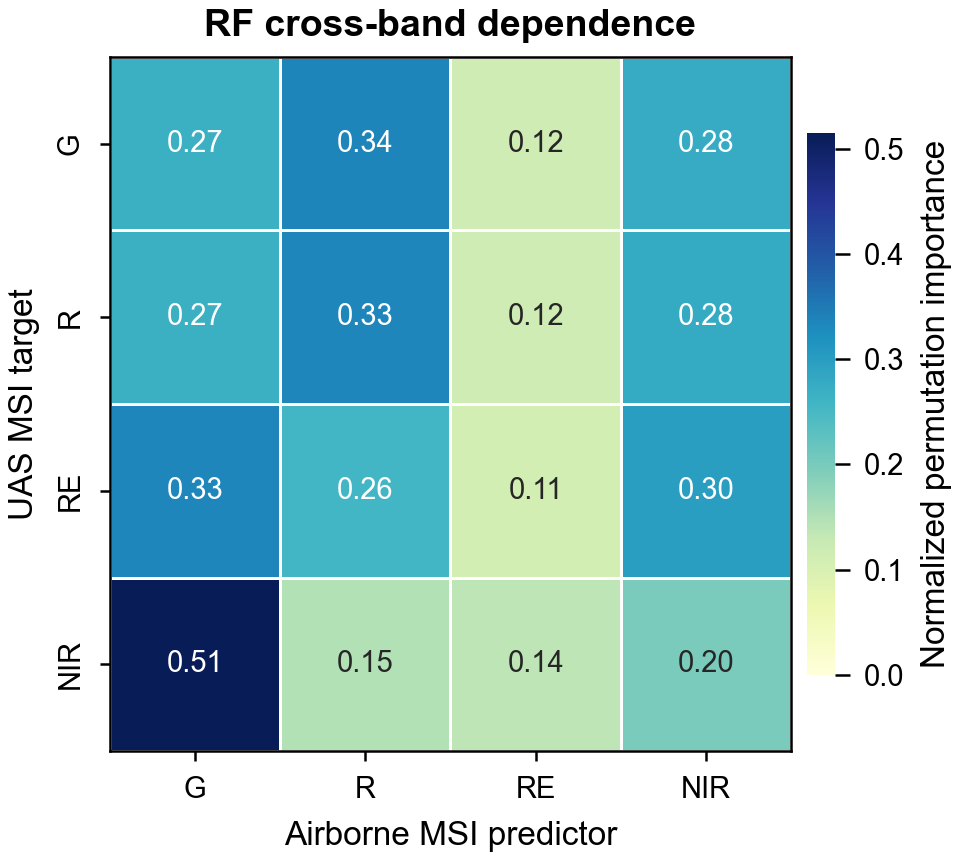

In [60]:
# RF Harmonization Explainability:
# What airborne MSI bands did RF use to predict each UAS band?

from sklearn.inspection import permutation_importance

print("\n--- RF harmonization explainability: permutation importance ---")

band_order = ["Green", "Red", "RedEdge", "NIR"]

drone_targets = {
    "Green": "Drone_G",
    "Red": "Drone_R",
    "RedEdge": "Drone_RE",
    "NIR": "Drone_NIR",
}

band_short = {
    "Green": "G",
    "Red": "R",
    "RedEdge": "RE",
    "NIR": "NIR",
}

feature_short = {
    "AVIRIS_Green": "G",
    "AVIRIS_Red": "R",
    "AVIRIS_RedEdge": "RE",
    "AVIRIS_NIR": "NIR",
}

importance_records = []

for band_name in band_order:
    print(f"Computing permutation importance for {band_name} target...")

    X = clean_data[simulated_msi_cols]
    y = clean_data[drone_targets[band_name]]

    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.30,
        random_state=42
    )

    rf = rf_models[band_name]

    perm = permutation_importance(
        rf,
        X_test,
        y_test,
        n_repeats=50,
        random_state=42,
        scoring="r2",
        n_jobs=-1
    )

    for feature, imp_mean, imp_std in zip(
        simulated_msi_cols,
        perm.importances_mean,
        perm.importances_std
    ):
        importance_records.append({
            "Target_Band": band_name,
            "Target_Label": band_short[band_name],
            "Airborne_Band": feature,
            "Airborne_Label": feature_short[feature],
            "Importance": max(imp_mean, 0),
            "Importance_SD": imp_std,
        })

importance_df = pd.DataFrame(importance_records)

# Normalize within each target band so rows sum to 1
importance_df["Normalized_Importance"] = (
    importance_df
    .groupby("Target_Band")["Importance"]
    .transform(lambda x: x / x.sum() if x.sum() > 0 else x)
)

importance_matrix = (
    importance_df
    .pivot(
        index="Target_Label",
        columns="Airborne_Label",
        values="Normalized_Importance"
    )
    .reindex(["G", "R", "RE", "NIR"])
    [["G", "R", "RE", "NIR"]]
)

print("\nNormalized permutation importance matrix:")
print(importance_matrix.round(3))


## Explainability heatmap

fig, ax = plt.subplots(figsize=(3.4, 3.05))

sns.heatmap(
    importance_matrix,
    ax=ax,
    cmap="YlGnBu",
    vmin=0,
    vmax=np.nanmax(importance_matrix.values),
    annot=True,
    fmt=".2f",
    annot_kws={"size": 7},
    linewidths=0.35,
    linecolor="white",
    cbar_kws={
        "label": "Normalized permutation importance",
        "shrink": 0.78,
        "pad": 0.02
    }
)

ax.set_xlabel("Airborne MSI predictor")
ax.set_ylabel("UAS MSI target")
ax.set_title("RF cross-band dependence", fontweight="bold", pad=5)

ax.tick_params(axis="both", length=2.5, width=0.6)

for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_linewidth(0.6)

fig.tight_layout()
plt.show()

In [61]:
# Multi-index LOOCV comparison
# Separate tables for band-harmonized and index-harmonized results
# Linear and Quadratic only

from sklearn.preprocessing import PolynomialFeatures
from sklearn.model_selection import LeaveOneOut, cross_val_predict


print("Phase 9: Multi-Index LOOCV Comparison")

eps = 1e-6
loo = LeaveOneOut()
poly = PolynomialFeatures(degree=2, include_bias=False)

# 1. Raw unharmonized airborne MSI indices

G_u = plot_data["AVIRIS_Green"].values
R_u = plot_data["AVIRIS_Red"].values
RE_u = plot_data["AVIRIS_RedEdge"].values
NIR_u = plot_data["AVIRIS_NIR"].values

raw_indices = {
    "NDVI": (NIR_u - R_u) / (NIR_u + R_u + eps),
    "SR": NIR_u / (R_u + eps),
    "GNDVI": (NIR_u - G_u) / (NIR_u + G_u + eps),
    "GRVI": (G_u - R_u) / (G_u + R_u + eps),
    "GDVI": NIR_u - G_u,
    "SAVI": ((NIR_u - R_u) / (NIR_u + R_u + 0.5 + eps)) * 1.5,
    "GSAVI": ((NIR_u - G_u) / (NIR_u + G_u + 0.5 + eps)) * 1.5,
    "OSAVI": ((NIR_u - R_u) / (NIR_u + R_u + 0.16 + eps)) * 1.16,
    "MSAVI2": 0.5 * (
        2 * NIR_u + 1
        - np.sqrt(np.maximum((2 * NIR_u + 1) ** 2 - 8 * (NIR_u - R_u), 0))
    ),
    "NDRE": (NIR_u - RE_u) / (NIR_u + RE_u + eps),
    "SR_RE": NIR_u / (RE_u + eps),
    "CI_RE": (NIR_u / (RE_u + eps)) - 1,
    "MTCI": (NIR_u - RE_u) / (RE_u - R_u + eps),
    "MSR": ((NIR_u / (R_u + eps)) - 1) / (
        np.sqrt(np.maximum(NIR_u / (R_u + eps), 0)) + 1
    ),
    "EVI2": 2.5 * (NIR_u - R_u) / (NIR_u + 2.4 * R_u + 1 + eps),
    "NIRv": ((NIR_u - R_u) / (NIR_u + R_u + eps)) * NIR_u,
    "MTVI2": (
        1.5 * (1.2 * (NIR_u - G_u) - 2.5 * (R_u - G_u))
        / np.sqrt(
            np.maximum(
                (2 * NIR_u + 1) ** 2
                - (6 * NIR_u - 5 * np.sqrt(np.maximum(R_u, 0)))
                - 0.5,
                eps
            )
        )
    ),
}

# 2. Band-harmonized indices from RF-predicted G/R/RE/NIR
# Rebuild explicitly for the 20 LAI plots to avoid variable overwrite

X_20_sites = plot_data[simulated_msi_cols]

G_bandcal_20 = rf_models["Green"].predict(X_20_sites)
R_bandcal_20 = rf_models["Red"].predict(X_20_sites)
RE_bandcal_20 = rf_models["RedEdge"].predict(X_20_sites)
NIR_bandcal_20 = rf_models["NIR"].predict(X_20_sites)

bandcal_indices = {
    "NDVI": (NIR_bandcal_20 - R_bandcal_20) / (NIR_bandcal_20 + R_bandcal_20 + eps),
    "SR": NIR_bandcal_20 / (R_bandcal_20 + eps),
    "GNDVI": (NIR_bandcal_20 - G_bandcal_20) / (NIR_bandcal_20 + G_bandcal_20 + eps),
    "GRVI": (G_bandcal_20 - R_bandcal_20) / (G_bandcal_20 + R_bandcal_20 + eps),
    "GDVI": NIR_bandcal_20 - G_bandcal_20,
    "SAVI": ((NIR_bandcal_20 - R_bandcal_20) / (NIR_bandcal_20 + R_bandcal_20 + 0.5 + eps)) * 1.5,
    "GSAVI": ((NIR_bandcal_20 - G_bandcal_20) / (NIR_bandcal_20 + G_bandcal_20 + 0.5 + eps)) * 1.5,
    "OSAVI": ((NIR_bandcal_20 - R_bandcal_20) / (NIR_bandcal_20 + R_bandcal_20 + 0.16 + eps)) * 1.16,
    "MSAVI2": 0.5 * (
        2 * NIR_bandcal_20 + 1
        - np.sqrt(np.maximum((2 * NIR_bandcal_20 + 1) ** 2 - 8 * (NIR_bandcal_20 - R_bandcal_20), 0))
    ),
    "NDRE": (NIR_bandcal_20 - RE_bandcal_20) / (NIR_bandcal_20 + RE_bandcal_20 + eps),
    "SR_RE": NIR_bandcal_20 / (RE_bandcal_20 + eps),
    "CI_RE": (NIR_bandcal_20 / (RE_bandcal_20 + eps)) - 1,
    "MTCI": (NIR_bandcal_20 - RE_bandcal_20) / (RE_bandcal_20 - R_bandcal_20 + eps),
    "MSR": ((NIR_bandcal_20 / (R_bandcal_20 + eps)) - 1) / (
        np.sqrt(np.maximum(NIR_bandcal_20 / (R_bandcal_20 + eps), 0)) + 1
    ),
    "EVI2": 2.5 * (NIR_bandcal_20 - R_bandcal_20) / (
        NIR_bandcal_20 + 2.4 * R_bandcal_20 + 1 + eps
    ),
    "NIRv": ((NIR_bandcal_20 - R_bandcal_20) / (NIR_bandcal_20 + R_bandcal_20 + eps)) * NIR_bandcal_20,
    "MTVI2": (
        1.5 * (1.2 * (NIR_bandcal_20 - G_bandcal_20) - 2.5 * (R_bandcal_20 - G_bandcal_20))
        / np.sqrt(
            np.maximum(
                (2 * NIR_bandcal_20 + 1) ** 2
                - (6 * NIR_bandcal_20 - 5 * np.sqrt(np.maximum(R_bandcal_20, 0)))
                - 0.5,
                eps
            )
        )
    ),
}

# 3. Direct index-harmonized indices
# Requires predicted_indices from direct RF index harmonization section

indexcal_indices = predicted_indices

index_names_multi = list(indices_list)
y_target = np.asarray(y_actual)


def fit_train_loocv(X, y):
    model = LinearRegression()
    model.fit(X, y)

    train_pred = model.predict(X)
    cv_pred = cross_val_predict(
        LinearRegression(),
        X,
        y,
        cv=loo
    )

    return {
        "Train_R2": r2_score(y, train_pred),
        "Train_RMSE": np.sqrt(mean_squared_error(y, train_pred)),
        "LOOCV_R2": r2_score(y, cv_pred),
        "LOOCV_RMSE": np.sqrt(mean_squared_error(y, cv_pred)),
        "Train_Preds": train_pred,
        "LOOCV_Preds": cv_pred,
    }


def make_design(X, form):
    if form == "Linear":
        return X

    if form == "Quadratic":
        return PolynomialFeatures(degree=2, include_bias=False).fit_transform(X)

    raise ValueError(f"Unsupported form: {form}")


def run_multi_index_comparison(harmon_indices_dict, harmonization_name, k_values=[2]):
    rows = []

    for k in k_values:
        for combo in itertools.combinations(index_names_multi, k):
            X_u_raw = np.column_stack([raw_indices[name] for name in combo])
            X_c_raw = np.column_stack([harmon_indices_dict[name] for name in combo])

            valid_mask = (
                np.isfinite(X_u_raw).all(axis=1)
                & np.isfinite(X_c_raw).all(axis=1)
                & np.isfinite(y_target)
            )

            X_u_raw = X_u_raw[valid_mask]
            X_c_raw = X_c_raw[valid_mask]
            y_clean = y_target[valid_mask]

            if len(y_clean) < 15:
                continue

            for form in ["Linear", "Quadratic"]:
                try:
                    X_u = make_design(X_u_raw, form)
                    X_c = make_design(X_c_raw, form)

                    u = fit_train_loocv(X_u, y_clean)
                    c = fit_train_loocv(X_c, y_clean)

                    rows.append({
                        "harmonization": harmonization_name,
                        "Features": " + ".join(combo),
                        "Form": form,
                        "K": k,

                        "raw_Train_R2": u["Train_R2"],
                        "raw_Train_RMSE": u["Train_RMSE"],
                        "harmon_Train_R2": c["Train_R2"],
                        "harmon_Train_RMSE": c["Train_RMSE"],
                        "Train_R2_Gain": c["Train_R2"] - u["Train_R2"],

                        "raw_LOOCV_R2": u["LOOCV_R2"],
                        "raw_LOOCV_RMSE": u["LOOCV_RMSE"],
                        "harmon_LOOCV_R2": c["LOOCV_R2"],
                        "harmon_LOOCV_RMSE": c["LOOCV_RMSE"],
                        "LOOCV_R2_Gain": c["LOOCV_R2"] - u["LOOCV_R2"],
                        "LOOCV_RMSE_Gain": u["LOOCV_RMSE"] - c["LOOCV_RMSE"],

                        "Actual_Y": y_clean,
                        "Preds_U": u["LOOCV_Preds"],
                        "Preds_C": c["LOOCV_Preds"],
                        "Train_Preds_U": u["Train_Preds"],
                        "Train_Preds_C": c["Train_Preds"],
                    })

                except Exception as e:
                    print(f"Skipped {harmonization_name}: {' + '.join(combo)} ({form}) | {e}")

    df = pd.DataFrame(rows)

    df_all = df.sort_values(
        by="harmon_LOOCV_R2",
        ascending=False
    )

    df_best_unique = (
        df_all
        .drop_duplicates(subset=["Features"], keep="first")
        .copy()
    )

    return df_all, df_best_unique


# 4. Run both comparisons separately

df_bandcal_multi_all, df_best_bandcal_multi = run_multi_index_comparison(
    bandcal_indices,
    harmonization_name="Band-harmonized",
    k_values=[2]
)

df_indexcal_multi_all, df_best_indexcal_multi = run_multi_index_comparison(
    indexcal_indices,
    harmonization_name="Index-harmonized",
    k_values=[2]
)


cols_to_print = [
    "Features",
    "Form",
    "raw_Train_R2",
    "harmon_Train_R2",
    "Train_R2_Gain",
    "raw_LOOCV_R2",
    "harmon_LOOCV_R2",
    "LOOCV_R2_Gain",
    "harmon_LOOCV_RMSE",
]

print("\n" + "-" * 150)
print(f"{'Top Two-Index Models: Band-harmonized vs Raw Airborne MSI':^150}")
print("-" * 150)
print(df_best_bandcal_multi[cols_to_print].round(3).head(10).to_string(index=False))

print("\n" + "-" * 150)
print(f"{'Top Two-Index Models: Index-harmonized vs Raw Airborne MSI':^150}")
print("-" * 150)
print(df_best_indexcal_multi[cols_to_print].round(3).head(10).to_string(index=False))


# Choose the table for downstream plotting.
# For band-harmonized:
df_best_unique_multi = df_best_bandcal_multi.copy()

# For index-harmonized instead, use:
# df_best_unique_multi = df_best_indexcal_multi.copy()

# Compact summary tables
# R2, RMSE, CV_R2, CV_RMSE for unharmonized and harmonized cases

summary_cols = [
    "Features",
    "Form",
    "raw_Train_R2",
    "raw_Train_RMSE",
    "raw_LOOCV_R2",
    "raw_LOOCV_RMSE",
    "harmon_Train_R2",
    "harmon_Train_RMSE",
    "harmon_LOOCV_R2",
    "harmon_LOOCV_RMSE",
]

rename_cols = {
    "raw_Train_R2": "raw_R2",
    "raw_Train_RMSE": "raw_RMSE",
    "raw_LOOCV_R2": "raw_CV_R2",
    "raw_LOOCV_RMSE": "raw_CV_RMSE",
    "harmon_Train_R2": "harmon_R2",
    "harmon_Train_RMSE": "harmon_RMSE",
    "harmon_LOOCV_R2": "harmon_CV_R2",
    "harmon_LOOCV_RMSE": "harmon_CV_RMSE",
}

bandcal_summary = (
    df_best_bandcal_multi[summary_cols]
    .rename(columns=rename_cols)
    .round(3)
)

indexcal_summary = (
    df_best_indexcal_multi[summary_cols]
    .rename(columns=rename_cols)
    .round(3)
)

print("\n" + "-" * 125)
print(f"{'Band-harmonized Multi-Index Models':^125}")
print("-" * 125)
print(bandcal_summary.head(15).to_string(index=False))

print("\n" + "-" * 125)
print(f"{'Index-harmonized Multi-Index Models':^125}")
print("-" * 125)
print(indexcal_summary.head(15).to_string(index=False))

Phase 9: Multi-Index LOOCV Comparison

------------------------------------------------------------------------------------------------------------------------------------------------------
                                              Top Two-Index Models: Band-harmonized vs Raw Airborne MSI                                               
------------------------------------------------------------------------------------------------------------------------------------------------------
      Features   Form  raw_Train_R2  harmon_Train_R2  Train_R2_Gain  raw_LOOCV_R2  harmon_LOOCV_R2  LOOCV_R2_Gain  harmon_LOOCV_RMSE
  GNDVI + NDRE Linear         0.044            0.417          0.372        -0.307            0.201          0.508              0.459
  GDVI + GSAVI Linear         0.282            0.332          0.050        -0.275            0.120          0.395              0.482
 GNDVI + CI_RE Linear         0.044            0.363          0.319        -0.301            0.113          0